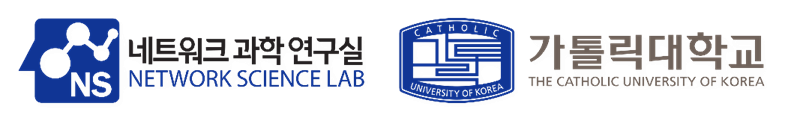

# Practice Code 11: Generative Graph Models & Diffusion

So far GNNs are encoders: they read a graph and output node or graph embeddings. 

This week we turn them around and build graph generators. 

Given graphs sampled from an unknown $p_{data}(G)$, we want to

1. learn a model $p_\theta(G) \approx p_{data}(G)$ (density estimation), and
2. sample new graphs $G_{new} \sim p_\theta(G)$.

| Part | Section | What we build |
|:--|:--|:--|
| Motivation, notation, permutation symmetry | 1 | The dataset, $n!$ adjacency matrices for one graph, invariance and equivariance |
| Classic / probabilistic models | 2 | Erdős–Rényi, Barabási–Albert, stochastic block model |
| Evaluating generated graphs | 3 | Degree / clustering / spectrum statistics, Wasserstein distance, MMD, uniqueness and novelty |
| Autoregressive | 4 | GraphRNN: BFS ordering, node-level + edge-level RNN, teacher forcing |
| Latent variable | 5 | GraphVAE: one-shot decoder, ELBO, graph matching |
| Adversarial | 6 | MolGAN-style GAN: Gumbel-softmax generator, GNN discriminator, reward network |
| Normalizing flow | 7 | GraphAF-style flow: change of variables, dequantization, masked parallel training |
| Diffusion | 8 | EDP-GNN (score matching + Langevin) and DiGress (discrete diffusion) |
| | 9 | Summary: all models side by side |

Our graphs have at most 20 nodes, so every model works on **dense** padded adjacency matrices `A: [B, 20, 20]` with a node mask `mask: [B, 20]` (1 = real node, 0 = padding). Every generator has the same interface, `sample_<model>(num) -> list of networkx graphs`, and every list of generated graphs goes through the same `evaluate(...)` function.

# 0. Setup

In [1]:
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch-geometric", "networkx", "scipy"])

In [2]:
import math, time, random, warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.optimize import linear_sum_assignment          # Hungarian algorithm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)
ROOT = "./data"
COLORS = {'Data': '#0b0b0b', 'ER': '#6250d6', 'BA': '#e34948', 'SBM': '#9a9a9a',           
          'GraphRNN': '#2a78d6', 'GraphVAE': '#eb6834', 'GAN': '#1baf7a', 'GraphAF': '#eda100',
          'EDP-GNN': '#e87ba4', 'DiGress': '#008300'}

Device: cuda


## 0.1. Graphs as padded dense matrices

* `nx_to_adj` / `adj_to_nx` convert between a networkx graph and a dense adjacency matrix padded to `N_MAX = 20` nodes.
* `pad_batch` stacks a list of graphs into `A: [B, N_MAX, N_MAX]` and `mask: [B, N_MAX]`.
* `sample_symmetric` samples an undirected graph from a matrix of edge probabilities (every pair $i<j$ independently).
* `draw_graphs` draws a list of small graphs in a grid.
* `DenseGCNLayer` is the GCN layer for padded batches: $H' = \hat A H W$ with $\hat A = D^{-1/2}(A + I)D^{-1/2}$. Padding nodes have no edges and are multiplied by 0, so they never influence the real nodes. GraphVAE, the GAN and GraphAF reuse it.

In [3]:
N_MAX = 20                                                    # maximum number of nodes

def nx_to_adj(G, n_max=N_MAX):
    """networkx graph -> dense adjacency A [n_max, n_max] (zero padded) and node mask [n_max]."""
    n = G.number_of_nodes()
    A = torch.zeros(n_max, n_max)
    A[:n, :n] = torch.tensor(nx.to_numpy_array(G, nodelist=sorted(G.nodes())), dtype=torch.float)
    mask = torch.zeros(n_max)
    mask[:n] = 1.0
    return A, mask

def adj_to_nx(A, mask=None):
    """Dense (0/1) adjacency [n, n] -> networkx graph. If a mask is given, only the nodes with mask = 1 are kept."""
    A = A.detach().cpu()
    idx = torch.arange(A.size(0)) if mask is None else mask.detach().cpu().nonzero().view(-1)
    sub = (A[idx][:, idx] > 0.5).int().numpy()
    G = nx.from_numpy_array(sub)
    G.remove_edges_from(nx.selfloop_edges(G))
    return G

def pad_batch(graphs, n_max=N_MAX):
    """List of networkx graphs -> A [B, n_max, n_max] and mask [B, n_max], on the device."""
    pairs = [nx_to_adj(G, n_max) for G in graphs]
    return torch.stack([a for a, _ in pairs]).to(device), torch.stack([m for _, m in pairs]).to(device)

def sample_symmetric(P):
    """Sample a symmetric 0/1 matrix: pair i < j is 1 with probability P[..., i, j] (no self-loops)."""
    upper = torch.bernoulli(torch.triu(P, diagonal=1))
    return upper + upper.transpose(-1, -2)

def draw_graphs(graphs, title=None, ncols=8, size=1.9, color='#2a78d6'):
    """Draw small graphs in a grid (n = number of nodes, m = number of edges)."""
    nrows = math.ceil(len(graphs) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, G in zip(axes.flat, graphs):
        nx.draw(G, nx.spring_layout(G, seed=0), ax=ax, node_size=22, node_color=color, edge_color='#888888', width=0.7)
        ax.set_title(f'n={G.number_of_nodes()}, m={G.number_of_edges()}', fontsize=7)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

class DenseGCNLayer(nn.Module):
    """GCN layer on padded batches: H' = D^{-1/2} (A + I) D^{-1/2} H W   (self-loops only on the real nodes)."""
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim, out_dim)

    def forward(self, H, A, mask):                            # H [B, n, d], A [B, n, n], mask [B, n]
        A_hat = A + torch.diag_embed(mask)
        d = A_hat.sum(-1).clamp(min=1)                        # degrees (with the self-loop)
        A_norm = A_hat / torch.sqrt(d[:, :, None] * d[:, None, :])
        return (A_norm @ self.lin(H)) * mask[..., None]       # padding nodes stay 0

# 1. Graphs as data and the permutation problem

## 1.1. The dataset: two-community graphs

We use small two-community graphs, in the style of the Community-small benchmark of GraphRNN. 

Every graph has two communities of $c \in \{6, \dots, 10\}$ nodes (12–20 nodes in total). 

Two nodes of the same community are linked with probability $p_{in} = 0.7$, two nodes of different communities with probability $p_{out} = 0.05$, and we keep only connected graphs. 

The node labels of every graph are shuffled: like real data, the graphs come with no canonical node order.

We generate 600 graphs: 400 to train the generators and 200 test graphs to evaluate them. 

Every model will generate `NUM_SAMPLES = 200` graphs.

400 training graphs | 200 test graphs
nodes per graph: 12-20 (mean 16.3)
edges per graph: 16-79 (mean 45.7)
mean density: 0.355 | mean clustering coefficient: 0.604


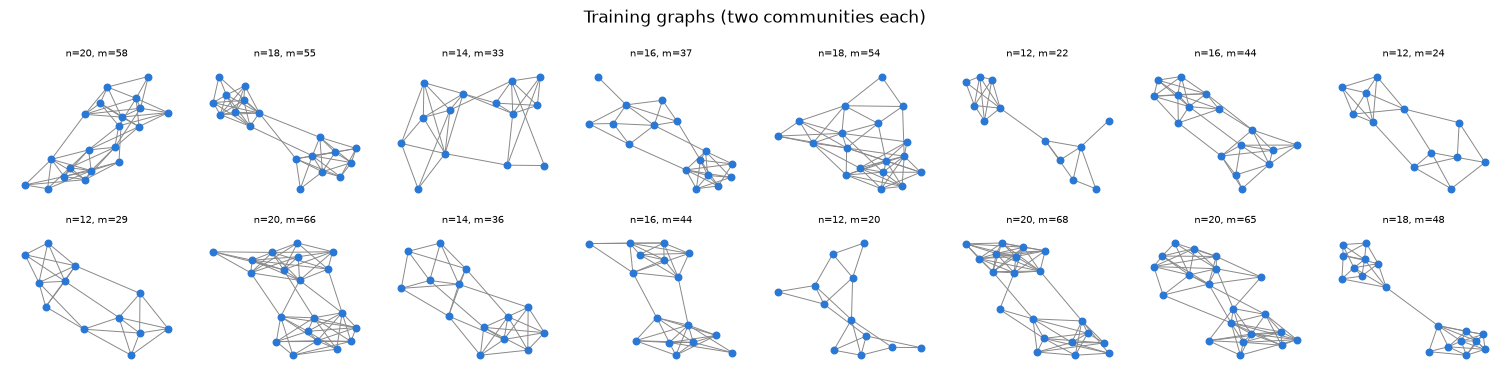

In [4]:
def community_graph(rng, size_range=(6, 10), p_in=0.7, p_out=0.05):
    """Two Erdős–Rényi communities of c nodes each, plus a few random edges between them (connected graphs only)."""
    while True:
        c = int(rng.integers(size_range[0], size_range[1] + 1))
        n = 2 * c
        community = np.array([0] * c + [1] * c)
        P = np.where(community[:, None] == community[None, :], p_in, p_out)   # edge probability of every pair
        upper = np.triu(rng.random((n, n)) < P, k=1)                           # decide every pair i < j once
        G = nx.from_numpy_array((upper | upper.T).astype(int))
        if nx.is_connected(G):
            perm = rng.permutation(n)                                          # shuffle the node labels
            return nx.relabel_nodes(G, {i: int(perm[i]) for i in range(n)})

rng = np.random.default_rng(0)
graphs = [community_graph(rng) for _ in range(600)]
train_graphs, test_graphs = graphs[:400], graphs[400:]
NUM_SAMPLES = 200                                             # number of graphs every model generates

n_nodes_train = np.array([G.number_of_nodes() for G in train_graphs])
n_edges = np.array([G.number_of_edges() for G in train_graphs])
density = np.mean([nx.density(G) for G in train_graphs])
print(f'{len(train_graphs)} training graphs | {len(test_graphs)} test graphs')
print(f'nodes per graph: {n_nodes_train.min()}-{n_nodes_train.max()} (mean {n_nodes_train.mean():.1f})')
print(f'edges per graph: {n_edges.min()}-{n_edges.max()} (mean {n_edges.mean():.1f})')
print(f'mean density: {density:.3f} | mean clustering coefficient: {np.mean([nx.average_clustering(G) for G in train_graphs]):.3f}')
draw_graphs(train_graphs[:16], 'Training graphs (two communities each)')

## 1.2. One graph, many adjacency matrices

If we relabel the nodes with a permutation matrix $\mathbf P$, the adjacency matrix becomes $\mathbf P\mathbf A\mathbf P^\top$. 

It is a different matrix that describes the same graph. 

A graph with $n$ nodes has up to $n!$ adjacency matrices, and a generative model should give all of them the same probability (permutation invariance):

$$p(\mathbf A, \mathbf X) = p(\mathbf P\mathbf A\mathbf P^\top, \mathbf P\mathbf X)\qquad \forall\, \mathbf P .$$

Same matrix?           False
Same graph (isomorphic)? True
n = 20 nodes -> up to n! = 2,432,902,008,176,640,000 adjacency matrices for this one graph


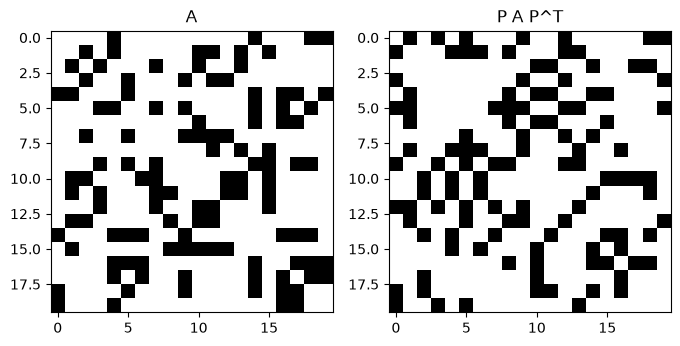

In [5]:
G = train_graphs[0]
n = G.number_of_nodes()
A = torch.tensor(nx.to_numpy_array(G, nodelist=range(n)), dtype=torch.float)
perm = torch.randperm(n)
P = torch.eye(n)[perm]                                      # permutation matrix: row i has a 1 in column perm[i]
A_perm = P @ A @ P.T                                        # ★ KEY: relabel the nodes, A -> P A P^T

print('Same matrix?          ', torch.equal(A, A_perm))
print('Same graph (isomorphic)?', nx.is_isomorphic(nx.from_numpy_array(A.numpy()), nx.from_numpy_array(A_perm.numpy())))
print(f'n = {n} nodes -> up to n! = {math.factorial(n):,} adjacency matrices for this one graph')

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, M, title in [(axes[0], A, 'A'), (axes[1], A_perm, 'P A P^T')]:
    ax.imshow(M, cmap='Greys')
    ax.set_title(title)
plt.show()

## 1.3. Invariant and equivariant functions

* A function that outputs one value per graph (a likelihood, a discriminator score) must be invariant: $f(\mathbf P\mathbf A\mathbf P^\top, \mathbf P\mathbf X) = f(\mathbf A, \mathbf X)$.
* A function that outputs one value per node or per edge (a denoiser, a score network) must be equivariant: the output is permuted in the same way as the input, $f(\mathbf P\mathbf A\mathbf P^\top, \mathbf P\mathbf X) = \mathbf P f(\mathbf A, \mathbf X)$.

GNN layers are equivariant because they aggregate neighbours with a symmetric operation (sum, mean). Summing the node embeddings then gives an invariant graph embedding. We check both properties numerically.

In [6]:
set_seed(0)
layer = DenseGCNLayer(4, 8)
X = torch.randn(n, 4)                                        # random node features
one = torch.ones(1, n)                                       # node mask of a single graph (batch of size 1)

H = layer(X[None], A[None], one)[0]                          # node embeddings      [n, 8]
H_perm = layer((P @ X)[None], A_perm[None], one)[0]          # embeddings after relabelling the input

print(f'Equivariance: max |f(PAP^T, PX) - P f(A, X)| = {(H_perm - P @ H).abs().max():.1e}')
print(f'Invariance:   max |sum f(PAP^T, PX) - sum f(A, X)| = {(H_perm.sum(0) - H.sum(0)).abs().max():.1e}')

Equivariance: max |f(PAP^T, PX) - P f(A, X)| = 6.0e-08
Invariance:   max |sum f(PAP^T, PX) - sum f(A, X)| = 4.8e-07


* The permuted matrix is different, but the graph is the same (isomorphic). Even this 16-node graph has more than $2\cdot 10^{13}$ adjacency matrices.
* The GCN layer is equivariant and its sum readout is invariant (differences of $10^{-7}$ are floating-point rounding). Every discriminator, encoder and score network of this notebook is built from such layers.
* An autoregressive model sees the graph as a sequence, so it must choose one node order: we will see how GraphRNN limits the number of orders with BFS.

# 2. Classic random-graph models

Graph distributions:

| Model | Generative rule | Parameter |
|:--|:--|:--|
| Erdős–Rényi $G(n, p)$ | every edge independently with probability $p$: $P(G) = p^m(1-p)^{\binom n2 - m}$ | $p$ = mean density |
| Barabási–Albert | each new node links to $m$ existing nodes with probability $\Pi(v_i) = k_i / \sum_j k_j$ | $m$ = mean degree / 2 |
| Stochastic block model | node $i$ is in block $z_i$; $P(A_{ij} = 1) = B_{z_i z_j}$ | block matrix $B$, from a 2-way split of every graph |

For every model we draw the number of nodes $n$ from the training graphs. ER and SBM both sample every pair independently from a matrix of edge probabilities, so they share the function `sample_from_P`.

ER: p = 0.355 | BA: m = 3 | SBM: B_in = 0.697, B_out = 0.055


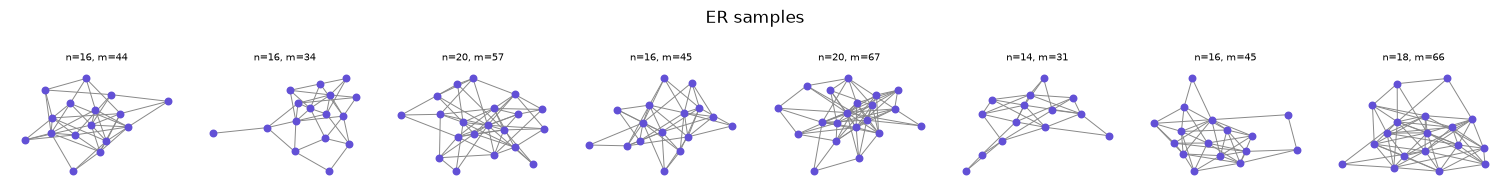

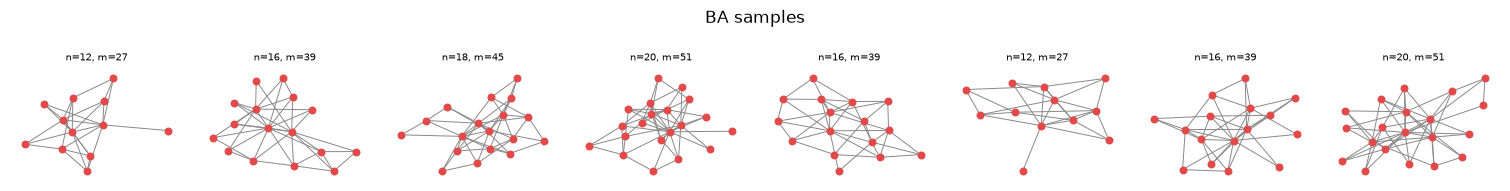

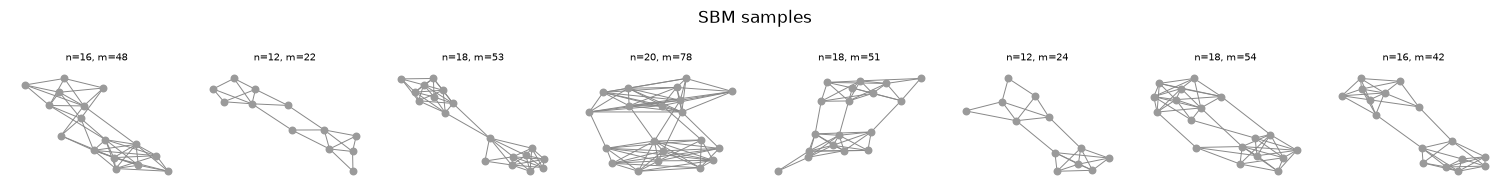

In [7]:
def sample_from_P(P, rng):
    """Sample an undirected graph in which pair (i, j) is an edge with probability P[i, j], independently."""
    n = P.shape[0]
    upper = np.triu(rng.random((n, n)) < P, k=1)
    return nx.from_numpy_array((upper | upper.T).astype(int))

def sample_er(num, p, rng):
    """Erdős–Rényi G(n, p)."""
    return [sample_from_P(np.full((n, n), p), rng) for n in rng.choice(n_nodes_train, num)]

def sample_ba(num, m, rng):
    """Barabási–Albert: start from a star on m+1 nodes; every new node links to m distinct existing nodes,
    chosen with probability proportional to their degree."""
    out = []
    for n in rng.choice(n_nodes_train, num):
        G = nx.star_graph(m)
        for v in range(m + 1, n):
            nodes, deg = np.array(G.nodes()), np.array([G.degree(u) for u in G.nodes()], dtype=float)
            targets = rng.choice(nodes, size=m, replace=False, p=deg / deg.sum())   # ★ KEY: Π(v_i) = k_i / Σ_j k_j
            G.add_edges_from((v, int(t)) for t in targets)
        out.append(G)
    return out

def sample_sbm(num, B, rng):
    """Stochastic block model with 2 blocks of equal size: P(A_ij = 1) = B[z_i, z_j]."""
    out = []
    for n in rng.choice(n_nodes_train, num):
        z = np.array([0] * (n // 2) + [1] * (n - n // 2))
        out.append(sample_from_P(B[z[:, None], z[None, :]], rng))               # ★ KEY: P(A_ij = 1) = B_{z_i z_j}
    return out

# Fit the parameters to the training graphs
p_er = density
m_ba = max(1, round(np.mean([2 * G.number_of_edges() / G.number_of_nodes() for G in train_graphs]) / 2))
within, between = [], []
for G in train_graphs:                                        # split every graph in two halves (Kernighan–Lin)
    S1, S2 = nx.algorithms.community.kernighan_lin_bisection(G, seed=0)
    e_in = sum(1 for u, v in G.edges() if (u in S1) == (v in S1))
    pairs_in = len(S1) * (len(S1) - 1) / 2 + len(S2) * (len(S2) - 1) / 2
    within.append(e_in / pairs_in)
    between.append((G.number_of_edges() - e_in) / (len(S1) * len(S2)))
B_sbm = np.array([[np.mean(within), np.mean(between)], [np.mean(between), np.mean(within)]])
print(f'ER: p = {p_er:.3f} | BA: m = {m_ba} | SBM: B_in = {B_sbm[0, 0]:.3f}, B_out = {B_sbm[0, 1]:.3f}')

rng = np.random.default_rng(1)
SAMPLES, TIMES = {}, {}
for name, sampler in [('ER', lambda: sample_er(NUM_SAMPLES, p_er, rng)), ('BA', lambda: sample_ba(NUM_SAMPLES, m_ba, rng)),
                      ('SBM', lambda: sample_sbm(NUM_SAMPLES, B_sbm, rng))]:
    t0 = time.time()
    SAMPLES[name] = sampler()
    TIMES[name] = time.time() - t0
    draw_graphs(SAMPLES[name][:8], f'{name} samples', color=COLORS[name])

* The SBM recovers the two communities: the Kernighan–Lin split finds them, and the fitted $B$ is close to the true generator ($0.7$ / $0.05$).
* ER has the right density but no communities: every pair is equally likely.
* BA grows hubs by preferential attachment. Our graphs have no hubs, so BA graphs look very different.

# 3. Evaluating generated graphs

Comparing two sets of graphs is hard: we cannot match graphs one by one (graph isomorphism is expensive, and generated graphs are new). 

GraphRNN compares distributions of graph statistics in three steps:

1. Statistics: For every graph we compute univariate distributions $M_i(G)$: the degree histogram, the clustering-coefficient histogram, and (as GRAN and DiGress do) the histogram of the eigenvalues of the normalised Laplacian (spectrum). GraphRNN also uses orbit counts, which need the ORCA tool; we skip them.
2. Distance between two graphs: the first Wasserstein (earth mover's) distance between their histograms. In 1-D it has a closed form, the area between the two cumulative distributions: $W(p, q) = \sum_k |F_p(k) - F_q(k)|\,\Delta$.
3. Distance between two sets: the squared MMD with the kernel $k(x, y) = \exp\big(-W(x, y)^2 / 2\sigma^2\big)$,
$$\mathrm{MMD}^2(p\,\|\,q) = \mathbb E_{x,y\sim p}[k(x,y)] + \mathbb E_{x,y\sim q}[k(x,y)] - 2\,\mathbb E_{x\sim p, y\sim q}[k(x,y)].$$
Lower is better; 0 means the two sets have the same statistics.

Two more numbers detect models that copy or repeat graphs:
* Unique: the share of generated graphs that are not isomorphic to an earlier generated graph (low = mode collapse).
* Novel: the share of generated graphs that are not isomorphic to any training graph (low = memorisation).

In [8]:
def degree_hist(G):
    """Histogram of the node degrees (bins 0, 1, ..., N_MAX - 1), normalised to sum to 1."""
    h = np.bincount([d for _, d in G.degree()], minlength=N_MAX)[:N_MAX].astype(float)
    return h / max(h.sum(), 1)

def clustering_hist(G, bins=100):
    """Histogram of the clustering coefficients of the nodes (100 bins on [0, 1])."""
    h = np.histogram(list(nx.clustering(G).values()), bins=bins, range=(0, 1))[0].astype(float)
    return h / max(h.sum(), 1)

def spectrum_hist(G, bins=200):
    """Histogram of the eigenvalues of the normalised Laplacian (200 bins on [0, 2])."""
    eig = np.linalg.eigvalsh(nx.normalized_laplacian_matrix(G).toarray()) if G.number_of_nodes() > 0 else []
    h = np.histogram(eig, bins=bins, range=(-1e-5, 2))[0].astype(float)
    return h / max(h.sum(), 1)

# statistic -> (function, bin width Δ, kernel bandwidth σ)
STATS = {'deg': (degree_hist, 1.0, 1.0), 'clus': (clustering_hist, 0.01, 0.1), 'spec': (spectrum_hist, 0.01, 0.1)}

def mmd(hists_p, hists_q, bin_width, sigma):
    """Squared MMD between two sets of histograms with the Gaussian-EMD kernel."""
    Fp = np.cumsum(np.array(hists_p), axis=1)                 # cumulative distributions [n_p, bins]
    Fq = np.cumsum(np.array(hists_q), axis=1)
    def kernel(F1, F2):
        W = np.abs(F1[:, None, :] - F2[None, :, :]).sum(-1) * bin_width   # ★ KEY: 1-D Wasserstein distance
        return np.exp(-W ** 2 / (2 * sigma ** 2))
    return kernel(Fp, Fp).mean() + kernel(Fq, Fq).mean() - 2 * kernel(Fp, Fq).mean()   # ★ KEY: MMD²

def isomorphic_to_any(G, candidates):
    """True if G is isomorphic to a graph of `candidates` (a dict: WL hash -> list of graphs)."""
    return any(nx.is_isomorphic(G, H) for H in candidates.get(nx.weisfeiler_lehman_graph_hash(G), []))

def hash_table(graph_list):
    table = {}
    for H in graph_list:
        table.setdefault(nx.weisfeiler_lehman_graph_hash(H), []).append(H)
    return table

def unique_share(gen_graphs):
    """Share of generated graphs that are not isomorphic to an earlier generated graph."""
    seen, unique = {}, 0
    for G in gen_graphs:
        if not isomorphic_to_any(G, seen):
            unique += 1
            seen.setdefault(nx.weisfeiler_lehman_graph_hash(G), []).append(G)
    return unique / len(gen_graphs)

TRAIN_TABLE = hash_table(train_graphs)
TEST_HISTS = {s: [f(G) for G in test_graphs] for s, (f, _, _) in STATS.items()}
RESULTS = {}

def evaluate(name, gen_graphs, seconds=None, show=True):
    """MMD (degree, clustering, spectrum) to the test graphs + connected / unique / novel shares."""
    row = {s: mmd([f(G) for G in gen_graphs], TEST_HISTS[s], w, sig) for s, (f, w, sig) in STATS.items()}
    row['connected'] = np.mean([G.number_of_nodes() > 0 and nx.is_connected(G) for G in gen_graphs])
    row['unique'] = unique_share(gen_graphs)
    row['novel'] = np.mean([not isomorphic_to_any(G, TRAIN_TABLE) for G in gen_graphs])
    row['nodes'] = np.mean([G.number_of_nodes() for G in gen_graphs])
    row['edges'] = np.mean([G.number_of_edges() for G in gen_graphs])
    row['time'] = seconds
    RESULTS[name] = row
    if show:
        t = f'{seconds:6.1f}s' if seconds is not None else '     -'
        print(f"{name:<10} MMD deg {row['deg']:.4f} | clus {row['clus']:.4f} | spec {row['spec']:.4f} | "
              f"connected {row['connected']:.0%} | unique {row['unique']:.0%} | novel {row['novel']:.0%} | "
              f"nodes {row['nodes']:.1f} | edges {row['edges']:.1f} | time {t}")
    return row

200 graphs of the training set are a sample of the true distribution: their MMD to the test set tells us how small an MMD can get with 200 graphs (it is not exactly 0, because both sets are finite). Then we score the three classic models.

In [9]:
evaluate('Data', train_graphs[:NUM_SAMPLES])
for name in ['ER', 'BA', 'SBM']:
    evaluate(name, SAMPLES[name], TIMES[name])

Data       MMD deg 0.0093 | clus 0.0053 | spec 0.0056 | connected 100% | unique 100% | novel 0% | nodes 16.5 | edges 47.0 | time      -
ER         MMD deg 0.0560 | clus 0.8218 | spec 0.3535 | connected 98% | unique 100% | novel 100% | nodes 16.2 | edges 44.6 | time    0.1s
BA         MMD deg 0.5479 | clus 0.5855 | spec 0.4622 | connected 100% | unique 100% | novel 100% | nodes 16.3 | edges 39.8 | time    0.2s
SBM        MMD deg 0.0044 | clus 0.0024 | spec 0.0009 | connected 95% | unique 100% | novel 100% | nodes 16.2 | edges 45.7 | time    0.1s


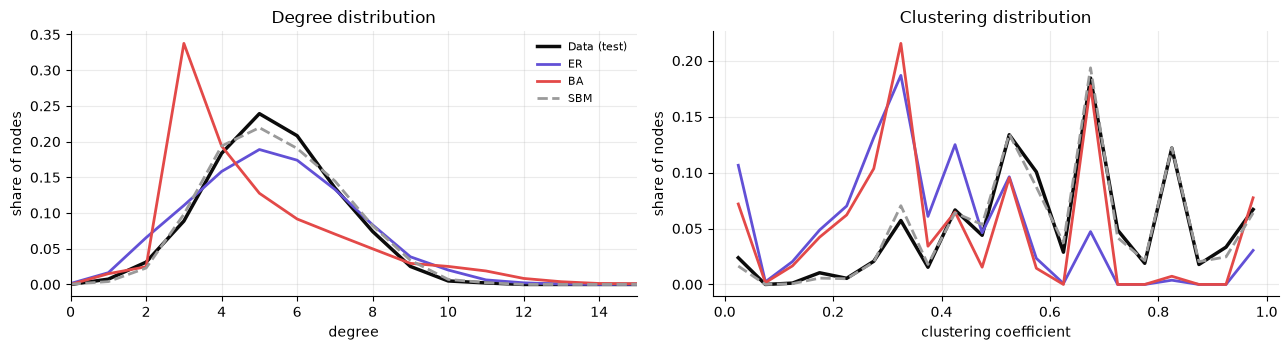

In [10]:
def plot_statistics(names):
    """Mean degree histogram and mean clustering histogram of the test graphs and of every model in `names`."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    sets = [('Data (test)', test_graphs)] + [(m, SAMPLES[m]) for m in names]
    for label, gs in sets:
        style = dict(color=COLORS[label.split(' ')[0]], lw=2.5 if label.startswith('Data') else 2,
                     ls='--' if label == 'SBM' else '-', label=label)
        axes[0].plot(np.mean([degree_hist(G) for G in gs], 0), **style)
        axes[1].plot(np.linspace(0.025, 0.975, 20), np.mean([clustering_hist(G, bins=20) for G in gs], 0), **style)
    axes[0].set(xlabel='degree', ylabel='share of nodes', title='Degree distribution', xlim=(0, 15))
    axes[1].set(xlabel='clustering coefficient', ylabel='share of nodes', title='Clustering distribution')
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].legend(fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()

plot_statistics(['ER', 'BA', 'SBM'])

* Data gives the floor: 0.009 (degree), 0.005 (clustering) and 0.006 (spectrum) for 200 vs. 200 graphs of the same distribution. A model whose MMD is close to these numbers is as good as we can measure. Differences of a few 0.001 are noise.
* SBM is at the floor on all three statistics (0.004 / 0.002 / 0.001): the true generator is a 2-block SBM. A hand-written model with the right structure is very hard to beat. It is not perfect, though: 6% of its graphs are disconnected, whereas our data generator rejects disconnected graphs.
* ER has the right density and a reasonable degree MMD (0.056), but it has no communities. Its clustering is far too low (MMD 0.82, the worst of all models): independent edges cannot create dense groups.
* BA fails on every statistic. Preferential attachment creates hubs and many nodes of degree $m = 3$ (the peak of the red curve).
* All classic samples are unique and novel and ER/BA are nevertheless poor models: uniqueness and novelty alone say nothing about quality.

The deep models below must learn the structure from the 400 training graphs, without being told that there are two communities.

# 4. GraphRNN: autoregressive generation

An autoregressive model writes the joint distribution as a product of conditionals:

$$p_{model}(\mathbf x;\theta) = \prod_{t=1}^{n} p_{model}(x_t \mid x_1, \dots, x_{t-1};\theta).$$

For graphs, $x_t$ is an action "add a node" or "add an edge". GraphRNN turns a graph into a sequence of sequences and generates it with two RNNs.

## 4.1. From a graph to a sequence, and why BFS

Fix a node order $\pi$. Node $i$ is added together with its edges to the nodes added before it: a binary vector $S_i^\pi$ (one row of the lower triangle of $\mathbf A$). The graph becomes $S^\pi = (S_1^\pi, \dots, S_{n-1}^\pi)$.

With a random order, node $i$ can link to any of the $i-1$ earlier nodes, so each row needs up to $n-1$ entries. With a BFS order, the neighbours of a node are added in a block. Once a node has been passed by the BFS, no later node can link to it, so node $i$ only needs to look back at its last $M$ predecessors, where $M$ (the bandwidth) is the largest distance in the order between two linked nodes. The rows shrink from $n-1$ to $M$ entries, and the number of distinct orders drops from $n!$ to the number of BFS orders.

Mean bandwidth: random order 14.3 | BFS order 8.0
M = 17 (largest BFS bandwidth over 20 random BFS orders of every training graph; random orders need up to 19)


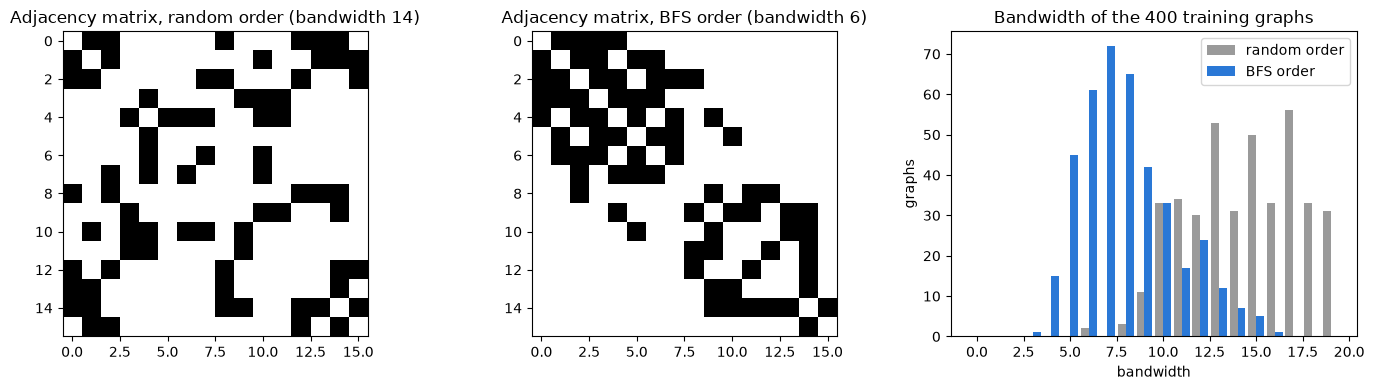

In [11]:
def bfs_order(G, rng):
    """Node order of a breadth-first search from a random start node."""
    start = int(rng.choice(list(G.nodes())))
    return [start] + [v for _, v in nx.bfs_edges(G, start)]

def random_order(G, rng):
    return [int(v) for v in rng.permutation(list(G.nodes()))]

def bandwidth(G, order):
    """Largest distance in the order between two linked nodes = how far back a new node must look."""
    pos = {v: i for i, v in enumerate(order)}
    return max(abs(pos[u] - pos[v]) for u, v in G.edges())

rng = np.random.default_rng(0)
bw_random = [bandwidth(G, random_order(G, rng)) for G in train_graphs]
bw_bfs = [bandwidth(G, bfs_order(G, rng)) for G in train_graphs]
M = max(bandwidth(G, bfs_order(G, rng)) for G in train_graphs for _ in range(20))   # 20 BFS orders per graph
print(f'Mean bandwidth: random order {np.mean(bw_random):.1f} | BFS order {np.mean(bw_bfs):.1f}')
print(f'M = {M} (largest BFS bandwidth over 20 random BFS orders of every training graph; random orders need up to {N_MAX - 1})')

G = train_graphs[3]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (title, order) in zip(axes[:2], [('random order', random_order(G, rng)), ('BFS order', bfs_order(G, rng))]):
    ax.imshow(nx.to_numpy_array(G, nodelist=order), cmap='Greys')
    ax.set_title(f'Adjacency matrix, {title} (bandwidth {bandwidth(G, order)})')
axes[2].hist([bw_random, bw_bfs], bins=np.arange(0, N_MAX + 1) - 0.5, label=['random order', 'BFS order'],
             color=['#9a9a9a', COLORS['GraphRNN']], rwidth=0.85)
axes[2].set(xlabel='bandwidth', ylabel='graphs', title='Bandwidth of the 400 training graphs')
axes[2].legend()
plt.tight_layout()
plt.show()

Now the conversion itself. Row $S_i$ has $M$ entries: $S_i[k] = 1$ if node $i$ links to node $i-1-k$ (its $(k+1)$-th most recent predecessor). After the last node we append an all-zero row: with a BFS order every node after the first links to at least one earlier node, so an empty row can only mean "the graph is finished" (the end-of-sequence token).

In [12]:
def graph_to_sequence(G, order, M):
    """S [n, M]: row i-1 holds the links of node i to nodes i-1, i-2, ..., i-M.
    The last row (all zeros) is the end-of-sequence token."""
    A = nx.to_numpy_array(G, nodelist=order)
    n = len(order)
    S = np.zeros((n, M))
    for i in range(1, n):
        for k in range(min(i, M)):
            S[i - 1, k] = A[i, i - 1 - k]
    return S

def sequence_to_graph(S):
    """Inverse of graph_to_sequence: read the rows until the first all-zero row."""
    G = nx.Graph()
    G.add_node(0)
    for i, row in enumerate(S, start=1):
        if row.sum() == 0:                                    # end of sequence
            break
        G.add_node(i)
        for k in np.nonzero(row)[0]:
            if i - 1 - k >= 0:
                G.add_edge(i, i - 1 - k)
    return G

G = train_graphs[3]
S = graph_to_sequence(G, bfs_order(G, rng), M)
print(f'Graph with {G.number_of_nodes()} nodes -> sequence of {S.shape[0]} rows x {S.shape[1]} entries. First 6 rows:')
print(S[:6].astype(int))
print('Round trip gives the same graph:', nx.is_isomorphic(G, sequence_to_graph(S)))

Graph with 16 nodes -> sequence of 16 rows x 17 entries. First 6 rows:
[[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [1 1 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0]]
Round trip gives the same graph: True


## 4.2. The model: a node-level RNN and an edge-level RNN

An RNN cell updates a hidden state $s_t = \sigma(W x_t + U s_{t-1})$ and outputs $y_t = V s_t$; we use GRU cells, a more expressive RNN cell. GraphRNN has two of them:

* the node-level RNN reads the previous row $S_{i-1}$ and keeps a summary of the graph generated so far; its state becomes the initial state of
* the edge-level RNN, which outputs the entries of $S_i$ one by one: $y_k = P(S_i[k] = 1)$, a Bernoulli probability.

Training uses teacher forcing the input of every step is the true previous row / entry. 

The loss is the binary cross-entropy of every entry,
$L = -\big[y^*\log y + (1-y^*)\log(1-y)\big].$

Every epoch draws a new random BFS order for every graph.

In [13]:
class GraphRNN(nn.Module):
    """Node-level GRU over the rows S_i + edge-level GRU over the entries of one row."""
    def __init__(self, M, node_hidden=128, edge_hidden=32):
        super().__init__()
        self.M = M
        self.node_embed = nn.Linear(M, 64)                    # embeds the previous row S_{i-1}
        self.node_rnn = nn.GRU(64, node_hidden, batch_first=True)
        self.to_edge_state = nn.Linear(node_hidden, edge_hidden)
        self.edge_embed = nn.Linear(1, 16)                    # embeds the previous entry S_i[k-1]
        self.edge_rnn = nn.GRU(16, edge_hidden, batch_first=True)
        self.edge_out = nn.Linear(edge_hidden, 1)             # logit of P(S_i[k] = 1)

    def forward(self, S):
        """Teacher forcing: S [B, L, M] (true rows) -> logits [B, L, M] for every entry."""
        B, L, M = S.shape
        # Node level: the input for row i is the true row i-1 (a row of ones = start-of-sequence token)
        node_in = torch.cat([torch.ones(B, 1, M, device=S.device), S[:, :-1]], dim=1)
        h, _ = self.node_rnn(self.node_embed(node_in))                  # [B, L, node_hidden]
        # ★ KEY: the node-level state initialises the edge-level RNN (one edge sequence per row)
        h0 = self.to_edge_state(h).reshape(1, B * L, -1)
        # Edge level: the input for entry k is the true entry k-1 (1 = start-of-sequence token)
        rows = S.reshape(B * L, M, 1)
        edge_in = torch.cat([torch.ones(B * L, 1, 1, device=S.device), rows[:, :-1]], dim=1)
        out, _ = self.edge_rnn(self.edge_embed(edge_in), h0)            # [B*L, M, edge_hidden]
        return self.edge_out(out).reshape(B, L, M)

def make_sequences(graph_list, M, rng, order_fn=bfs_order):
    """S [B, N_MAX, M] (zero padded) and row_mask [B, N_MAX] (1 for the real rows, EOS row included)."""
    S = torch.zeros(len(graph_list), N_MAX, M)
    row_mask = torch.zeros(len(graph_list), N_MAX)
    for b, G in enumerate(graph_list):
        seq = graph_to_sequence(G, order_fn(G, rng), M)
        S[b, :len(seq)] = torch.tensor(seq, dtype=torch.float)
        row_mask[b, :len(seq)] = 1.0
    return S.to(device), row_mask.to(device)

def train_graphrnn(graph_list, M, epochs=300, batch_size=32, lr=0.003, seed=0, order_fn=bfs_order):
    set_seed(seed)
    rng = np.random.default_rng(seed)
    model = GraphRNN(M).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[epochs // 2, 3 * epochs // 4], gamma=0.3)
    losses = []
    for epoch in range(epochs):
        perm, total = rng.permutation(len(graph_list)), 0.0
        for start in range(0, len(graph_list), batch_size):
            S, row_mask = make_sequences([graph_list[i] for i in perm[start:start + batch_size]], M, rng, order_fn)
            logits = model(S)
            # ★ KEY: binary cross-entropy of every entry of every real row
            bce = F.binary_cross_entropy_with_logits(logits, S, reduction='none')
            loss = (bce * row_mask[..., None]).sum() / (row_mask.sum() * M)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item()
        sched.step()
        losses.append(total / math.ceil(len(graph_list) / batch_size))
    return model, losses

## 4.3. Sampling

At test time there is no ground truth. #

At every step we sample the entry from the predicted Bernoulli distribution and feed the sample back as the next input. 

A graph stops at the first all-zero row (or at `N_MAX` nodes).

Training loss: first epoch 0.499 -> last epoch 0.169
GraphRNN   MMD deg 0.0093 | clus 0.0488 | spec 0.0198 | connected 100% | unique 100% | novel 100% | nodes 15.8 | edges 43.1 | time   66.8s


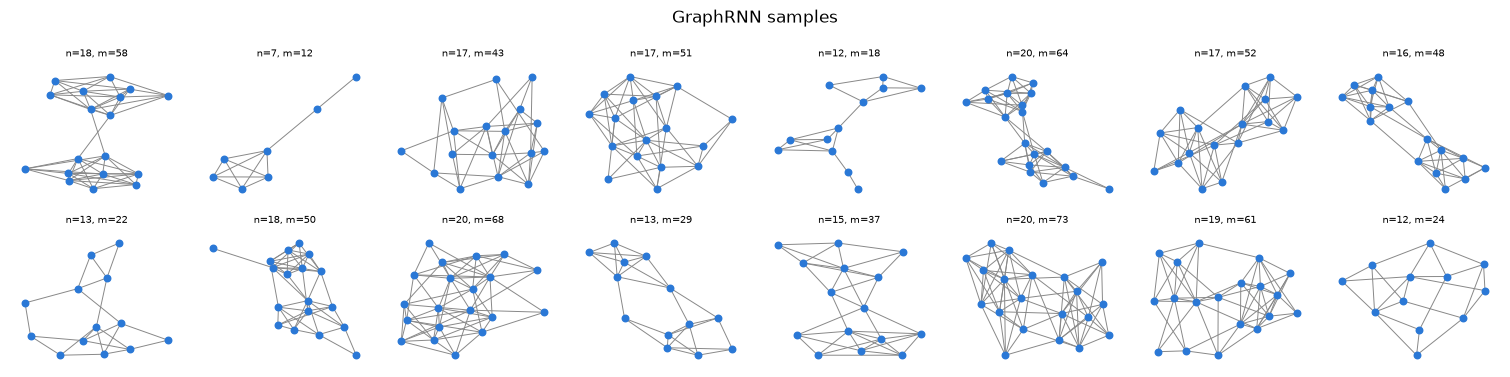

In [14]:
@torch.no_grad()
def sample_graphrnn(model, num):
    model.eval()
    M = model.M
    S = torch.zeros(num, N_MAX - 1, M, device=device)
    x, hidden = torch.ones(num, 1, M, device=device), None             # start-of-sequence row
    for r in range(N_MAX - 1):                                         # row r describes node r + 1
        h, hidden = model.node_rnn(model.node_embed(x), hidden)
        h_edge = model.to_edge_state(h[:, 0])[None]                    # [1, num, edge_hidden]
        prev = torch.ones(num, 1, 1, device=device)                    # start-of-sequence entry
        for k in range(M):
            out, h_edge = model.edge_rnn(model.edge_embed(prev), h_edge)
            p = torch.sigmoid(model.edge_out(out[:, 0]))               # [num, 1]
            bit = torch.bernoulli(p) if k <= r else torch.zeros_like(p)   # node r+1 has only r+1 predecessors
            S[:, r, k] = bit[:, 0]                                     # ★ KEY: sample from the predicted distribution
            prev = bit[:, None]                                        # ★ KEY: the model's own sample is the next input
        x = S[:, r:r + 1]
    model.train()
    return [sequence_to_graph(s) for s in S.cpu().numpy()]

t0 = time.time()
graphrnn, rnn_losses = train_graphrnn(train_graphs, M)
SAMPLES['GraphRNN'] = sample_graphrnn(graphrnn, NUM_SAMPLES)
TIMES['GraphRNN'] = time.time() - t0
print(f'Training loss: first epoch {rnn_losses[0]:.3f} -> last epoch {rnn_losses[-1]:.3f}')
evaluate('GraphRNN', SAMPLES['GraphRNN'], TIMES['GraphRNN'])
draw_graphs(SAMPLES['GraphRNN'][:16], 'GraphRNN samples', color=COLORS['GraphRNN'])

# 5. GraphVAE

GraphRNN needs one network call per entry of the sequence. 

GraphVAE skips the sequence: the decoder outputs the whole graph at once as a probabilistic fully connected graph with $k = 20$ nodes:
* $p_i$: probability that node $i$ exists,
* $P_{ij}$: probability that edge $(i, j)$ exists, all independent given $z$.

The model is a VAE:
* Encoder $q_\phi(z\mid G)$: a GCN, a sum pooling (invariant) and two linear heads for the mean $\mu$ and the log-variance $\log\sigma^2$ of a Gaussian.
* Decoder $p_\theta(G\mid z)$: an MLP from $z$ to the $k$ node logits and the $k(k-1)/2$ edge logits.
* Prior $p(z) = \mathcal N(0, I)$.

It is trained by minimising the negative ELBO:

$$\mathcal L(\phi,\theta; G) = \mathbb E_{q_\phi(z\mid G)}\big[-\log p_\theta(G\mid z)\big] + \mathrm{KL}\big(q_\phi(z\mid G)\,\|\,p(z)\big).$$

The expectation uses one sample $z = \mu + \sigma\odot\epsilon$, $\epsilon\sim\mathcal N(0, I)$ (the reparameterisation trick), and the KL of two Gaussians has a closed form, $\mathrm{KL} = -\frac12\sum_d\big(1 + \log\sigma_d^2 - \mu_d^2 - \sigma_d^2\big)$.

In [15]:
class GraphVAE(nn.Module):
    """GCN encoder -> (mu, logvar); MLP decoder z -> node logits [k] and symmetric edge logits [k, k]."""
    def __init__(self, k=N_MAX, hidden=64, latent=16):
        super().__init__()
        self.k, self.latent = k, latent
        self.gcn1, self.gcn2 = DenseGCNLayer(2, hidden), DenseGCNLayer(hidden, hidden)
        self.to_mu, self.to_logvar = nn.Linear(hidden, latent), nn.Linear(hidden, latent)
        self.iu = torch.triu_indices(k, k, offset=1).to(device)          # the k(k-1)/2 pairs i < j
        self.decoder = nn.Sequential(nn.Linear(latent, 256), nn.ReLU(), nn.Linear(256, 512), nn.ReLU(),
                                     nn.Linear(512, k + self.iu.size(1)))

    def encode(self, A, mask):
        X = torch.stack([mask, A.sum(-1) / self.k], dim=-1)             # node features: 1 and the scaled degree
        H = F.relu(self.gcn1(X, A, mask))
        H = F.relu(self.gcn2(H, A, mask))
        g = H.sum(dim=1)                                                 # sum pooling: invariant graph embedding
        return self.to_mu(g), self.to_logvar(g)

    def decode(self, z):
        out = self.decoder(z)
        node_logits = out[:, :self.k]
        edge_logits = torch.zeros(z.size(0), self.k, self.k, device=z.device)
        edge_logits[:, self.iu[0], self.iu[1]] = out[:, self.k:]
        return node_logits, edge_logits + edge_logits.transpose(1, 2)    # symmetric (the diagonal is never used)

## 5.1. The node-ordering problem and graph matching

The decoder outputs its nodes in some order, and the training graph comes in another (random) order. Node 1 of the target may be generated as node 4.

If we compare $\mathbf A$ and $\mathbf P$ entry by entry without aligning them, the loss punishes a correct graph that is simply listed in a different order.

GraphVAE therefore first matches the target nodes to the predicted nodes, and only then computes the reconstruction loss.

1. Start: match by degree. Target node $a$ goes to the predicted node $i$ whose expected degree $\sum_j P_{ij}$ is closest to $\deg(a)$ (Hungarian algorithm on the cost $|\deg(a) - \sum_j P_{ij}|$).
2. Improve (5 times): keep the current assignment $\pi$ of the other nodes fixed and score every move "target node $a$ → predicted node $i$" by the log-likelihood of $a$'s edges,
$\;\mathrm{gain}[a, i] = \sum_b A_{ab}\log P_{i\pi(b)} + (1 - A_{ab})\log(1 - P_{i\pi(b)})\;$ (+ the node term), then solve the assignment again.

After matching, the target is reordered ($\mathbf A' = \Pi^\top\mathbf A\,\Pi$) and compared entry by entry with the prediction.

In [16]:
def match_graph(A, mask, P_edge, p_node, iters=5):
    """Assignment pi (target node a -> predicted node pi[a]) that aligns the target graph (A, mask) with the
    predicted probabilistic graph (P_edge, p_node). All inputs are numpy arrays of size k."""
    k = A.shape[0]
    L1, L0 = np.log(P_edge + 1e-9), np.log(1 - P_edge + 1e-9)
    node_gain = np.outer(mask, np.log(p_node + 1e-9)) + np.outer(1 - mask, np.log(1 - p_node + 1e-9))   # [a, i]
    # 1. start: match the degrees
    _, pi = linear_sum_assignment(np.abs(A.sum(1)[:, None] - P_edge.sum(1)[None, :]) - node_gain)
    # 2. improve: one Hungarian step with the other nodes fixed, repeated
    for _ in range(iters):
        Pi = np.eye(k)[pi]                                               # Pi[a, pi[a]] = 1
        gain = A @ Pi @ L1.T + (1 - A - np.eye(k)) @ Pi @ L0.T + node_gain   # gain[a, i]
        _, pi = linear_sum_assignment(-gain)
    return pi

def align_targets(A, mask, P_edge, p_node):
    """Reorder every target graph of the batch to the node order of the prediction (A' = Pi^T A Pi)."""
    A_np, m_np, P_np, p_np = (t.detach().cpu().numpy() for t in (A, mask, P_edge, p_node))
    Pis = np.stack([np.eye(A.size(1))[match_graph(A_np[b], m_np[b], P_np[b], p_np[b])] for b in range(A.size(0))])
    Pis = torch.tensor(Pis, dtype=torch.float, device=A.device)
    # ★ KEY: permute the target with the matching before computing the loss
    return Pis.transpose(1, 2) @ A @ Pis, (Pis.transpose(1, 2) @ mask[..., None])[..., 0]

## 5.2. Training with and without matching

We train two GraphVAEs with the same settings, one without matching (the target is used in its random order) and one with matching.

In [17]:
def graphvae_loss(model, A, mask, matching=True, beta=1.0):
    mu, logvar = model.encode(A, mask)
    z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)             # ★ KEY: reparameterisation trick
    node_logits, edge_logits = model.decode(z)
    if matching:
        A, mask = align_targets(A, mask, torch.sigmoid(edge_logits), torch.sigmoid(node_logits))
    i, j = model.iu
    rec_nodes = F.binary_cross_entropy_with_logits(node_logits, mask, reduction='none').sum(1)
    rec_edges = F.binary_cross_entropy_with_logits(edge_logits[:, i, j], A[:, i, j], reduction='none').sum(1)
    kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(1)            # ★ KEY: KL(q(z|G) || N(0, I))
    loss = (rec_nodes + rec_edges + beta * kl).mean()                   # ★ KEY: negative ELBO
    return loss, rec_edges.mean().item(), kl.mean().item()

def train_graphvae(graph_list, matching=True, epochs=300, batch_size=32, lr=0.001, seed=0):
    set_seed(seed)
    model = GraphVAE().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    A_all, mask_all = pad_batch(graph_list)
    history = []
    for epoch in range(epochs):
        perm = torch.randperm(len(graph_list))
        for start in range(0, len(graph_list), batch_size):
            idx = perm[start:start + batch_size]
            loss, rec, kl = graphvae_loss(model, A_all[idx], mask_all[idx], matching)
            opt.zero_grad()
            loss.backward()
            opt.step()
        history.append((loss.item(), rec, kl))
    return model, history

@torch.no_grad()
def decode_graphs(model, z):
    node_logits, edge_logits = model.decode(z)
    mask = (torch.sigmoid(node_logits) > 0.5).float()                   # the nodes that exist
    A = sample_symmetric(torch.sigmoid(edge_logits))                    # independent Bernoulli edges
    return [adj_to_nx(A[b], mask[b]) for b in range(z.size(0))]

def sample_graphvae(model, num):
    return decode_graphs(model, torch.randn(num, model.latent, device=device))   # z ~ p(z) = N(0, I)

@torch.no_grad()
def reconstruction_accuracy(model, graph_list):
    """Share of correctly reconstructed node pairs (decoding z = mu, after the best matching)."""
    A, mask = pad_batch(graph_list)
    mu, _ = model.encode(A, mask)
    node_logits, edge_logits = model.decode(mu)
    P = torch.sigmoid(edge_logits)
    A_al, _ = align_targets(A, mask, P, torch.sigmoid(node_logits))
    i, j = model.iu
    return ((P[:, i, j] > 0.5).float() == A_al[:, i, j]).float().mean().item()

VAE = {}
for matching in [False, True]:
    name = 'GraphVAE' if matching else 'GraphVAE (no matching)'
    t0 = time.time()
    VAE[name], hist = train_graphvae(train_graphs, matching=matching)
    SAMPLES[name] = sample_graphvae(VAE[name], NUM_SAMPLES)
    TIMES[name] = time.time() - t0
    print(f'{name}: last epoch: edge reconstruction loss {hist[-1][1]:.1f} nats/graph, KL {hist[-1][2]:.1f} | '
          f'test reconstruction accuracy {reconstruction_accuracy(VAE[name], test_graphs):.3f}')
for name in ['GraphVAE (no matching)', 'GraphVAE']:
    evaluate(name, SAMPLES[name], TIMES[name])

GraphVAE (no matching): last epoch: edge reconstruction loss 85.7 nats/graph, KL 3.3 | test reconstruction accuracy 0.767
GraphVAE: last epoch: edge reconstruction loss 59.5 nats/graph, KL 3.1 | test reconstruction accuracy 0.867
GraphVAE (no matching) MMD deg 0.3059 | clus 0.7810 | spec 0.5148 | connected 92% | unique 100% | novel 100% | nodes 13.8 | edges 31.0 | time   40.0s
GraphVAE   MMD deg 0.3513 | clus 0.4077 | spec 0.3570 | connected 56% | unique 100% | novel 100% | nodes 13.8 | edges 27.7 | time   93.5s


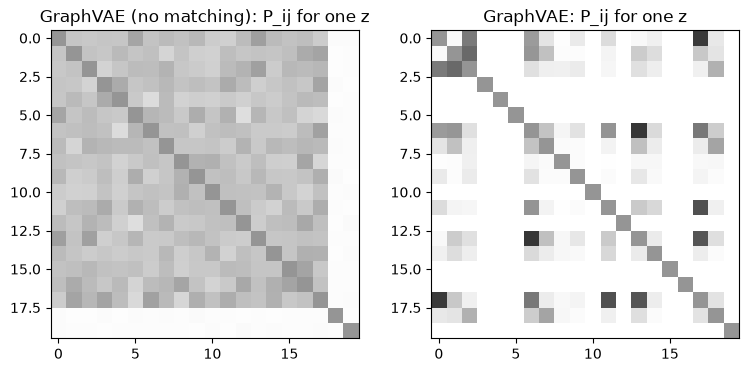

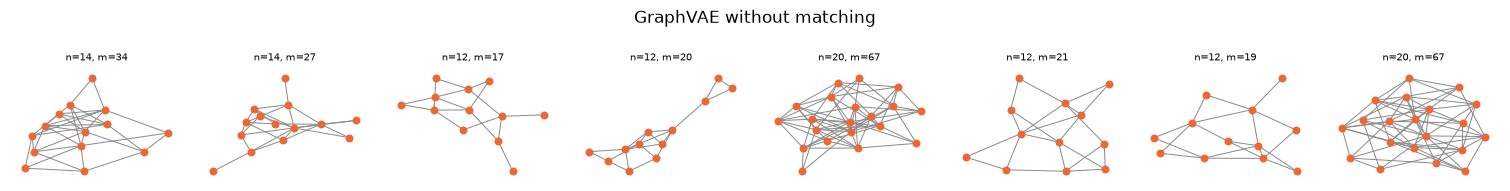

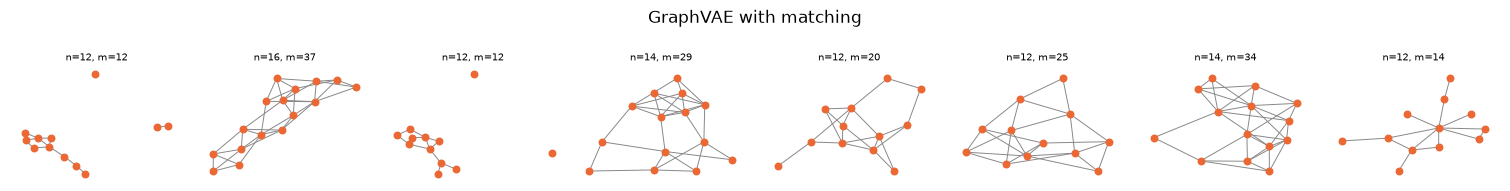

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
with torch.no_grad():
    z = torch.randn(1, 16, device=device)
    for ax, name in zip(axes, ['GraphVAE (no matching)', 'GraphVAE']):
        ax.imshow(torch.sigmoid(VAE[name].decode(z)[1])[0].cpu(), cmap='Greys', vmin=0, vmax=1)
        ax.set_title(f'{name}: P_ij for one z')
plt.show()
draw_graphs(SAMPLES['GraphVAE (no matching)'][:8], 'GraphVAE without matching', color=COLORS['GraphVAE'])
draw_graphs(SAMPLES['GraphVAE'][:8], 'GraphVAE with matching', color=COLORS['GraphVAE'])

## 5.3. Where should we sample $z$? The "prior hole"

The KL term pulls every $q_\phi(z\mid G)$ towards $\mathcal N(0, I)$, but only on average traded off against the reconstruction. 

std of mu over the training graphs, per latent dimension: [0.36 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.02
 0.02 0.02]
mean posterior std sigma, per latent dimension:           [0.04 0.96 0.95 0.97 0.92 0.96 0.95 0.99 1.   0.96 0.97 0.98 1.02 0.96
 0.99 0.95]
most used dimension: 0 | correlation of mu_0 with the number of nodes: -0.99


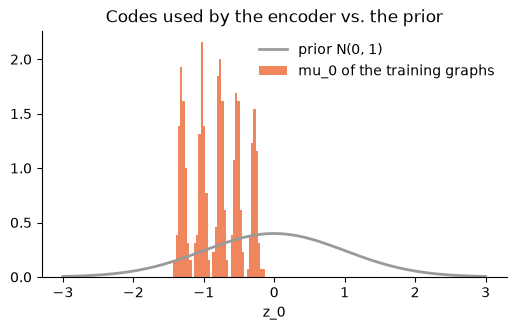

In [19]:
with torch.no_grad():
    A_tr, mask_tr = pad_batch(train_graphs)
    mu, logvar = VAE['GraphVAE'].encode(A_tr, mask_tr)
sd_mu, sigma_post = mu.std(0), torch.exp(0.5 * logvar).mean(0)
d = int(sd_mu.argmax())
corr = np.corrcoef(mask_tr.sum(1).cpu(), mu[:, d].cpu())[0, 1]
print('std of mu over the training graphs, per latent dimension:', sd_mu.cpu().numpy().round(2))
print('mean posterior std sigma, per latent dimension:          ', sigma_post.cpu().numpy().round(2))
print(f'most used dimension: {d} | correlation of mu_{d} with the number of nodes: {corr:.2f}')

plt.figure(figsize=(6, 3.2))
grid_z = np.linspace(-3, 3, 200)
plt.plot(grid_z, np.exp(-grid_z ** 2 / 2) / np.sqrt(2 * np.pi), color='#9a9a9a', lw=2, label='prior N(0, 1)')
plt.hist(mu[:, d].cpu(), bins=40, density=True, color=COLORS['GraphVAE'], alpha=0.8, label=f'mu_{d} of the training graphs')
plt.xlabel(f'z_{d}'); plt.legend(frameon=False); plt.title('Codes used by the encoder vs. the prior')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

The encoder uses essentially one latent dimension: it stores the size of the graph there, in a narrow range, with a tiny posterior variance. The other dimensions carry no information about the graph: their posterior equals the prior ($\sigma \approx 1$), the decoder ignores them, and their KL is 0. Most samples $z\sim\mathcal N(0, I)$ fall outside the range of the codes the decoder was trained on: a hole in the latent space.

A simple remedy is to sample from the aggregate posterior $q(z) = \frac1N\sum_G q_\phi(z\mid G)$ instead of the prior: pick a random training graph $G$ and draw $z = \mu_G + \sigma_G\,\epsilon$. The decoded graph is a *new* graph (its edges are sampled), not a copy of $G$.

GraphVAE   MMD deg 0.3513 | clus 0.4077 | spec 0.3570 | connected 56% | unique 100% | novel 100% | nodes 13.8 | edges 27.7 | time   93.5s
GraphVAE (agg. posterior) MMD deg 0.0579 | clus 0.2826 | spec 0.1073 | connected 90% | unique 100% | novel 100% | nodes 16.0 | edges 42.2 | time   93.5s


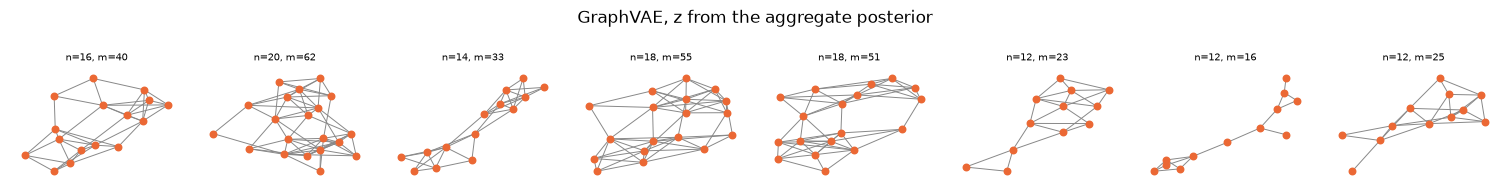

In [20]:
with torch.no_grad():
    idx = torch.randint(len(train_graphs), (NUM_SAMPLES,))
    z = mu[idx] + torch.exp(0.5 * logvar[idx]) * torch.randn(NUM_SAMPLES, mu.size(1), device=device)
SAMPLES['GraphVAE (agg. posterior)'] = decode_graphs(VAE['GraphVAE'], z)
TIMES['GraphVAE (agg. posterior)'] = TIMES['GraphVAE']
for name in ['GraphVAE', 'GraphVAE (agg. posterior)']:
    evaluate(name, SAMPLES[name], TIMES[name])
draw_graphs(SAMPLES['GraphVAE (agg. posterior)'][:8], 'GraphVAE, z from the aggregate posterior', color=COLORS['GraphVAE'])

* The encoder uses one latent dimension ($z_0$). Its codes form a few narrow clusters and their correlation with the number of nodes is −0.99: $z_0$ encodes the size of the graph (12, 14, ..., 20 nodes). The posterior standard deviation of this dimension is tiny (0.05).
* The 15 other dimensions are unused: their posterior equals the prior ($\sigma\approx 1$). This is posterior collapse of these dimensions: the KL term makes it cheaper to ignore them.
* The codes lie in $[-1.4, -0.2]$, where the prior puts only a third of its mass. Two thirds of the prior samples (e.g. every $z_0 > 0$) fall where the decoder was never trained, and it extrapolates badly: hence the wrong sizes (13.8 nodes on average).
* Sampling from the aggregate posterior fixes the size (15.9 nodes) and improves every MMD: degree 0.21 → 0.06, clustering 0.45 → 0.31, spectrum 0.30 → 0.13.
* GraphVAE stays the weakest learned model, for three reasons:
  1. given $z$, the 190 edges are independent Bernoulli variables;
  2. one MLP must output the whole graph at once;
  3. the matching is approximate.

  This is why GraphVAE targets small graphs only.

# 6. A MolGAN

GraphVAE needs a likelihood $p_\theta(G\mid z)$, and therefore a node matching. A GAN never computes a likelihood. A generator $G_\theta$ maps noise $z\sim p(z)$ to a graph, and a discriminator $D_\phi$ says whether a graph is real or generated. The generator may list its nodes in any order, because the discriminator only looks at the graph.

Minimax game:

$$\min_\theta\max_\phi\;\mathbb E_{x\sim p_{data}}\big[\log D_\phi(x)\big] + \mathbb E_{z\sim p(z)}\big[\log\big(1 - D_\phi(G_\theta(z))\big)\big].$$

MolGAN: 
* Generator: an MLP outputs, for every node, logits for "absent / present", and for every pair $i<j$, logits for "no edge / edge". A graph is discrete, so sampling it is not differentiable. MolGAN uses the straight-through Gumbel-softmax the forward pass uses a hard one-hot sample, the backward pass the gradient of a soft (relaxed) sample.
* Discriminator GCN layers and a sum pooling, followed by an MLP. It is permutation invariant so the generator is never punished for its node order. A GCN cannot count triangles (the 1-WL limit of message passing), but the clustering coefficient is the key property of our graphs. We therefore give every node its degree and its local clustering coefficient $\mathrm{tri}_i / \binom{d_i}{2}$, with $\mathrm{tri}_i = (\mathbf A^3)_{ii}/2$, as input features. Both are differentiable functions of $\mathbf A$, so the generator still receives gradients.

In [21]:
class Generator(nn.Module):
    """MLP: z -> logits of node existence [k, 2] and of every pair i < j [k(k-1)/2, 2], sampled with hard Gumbel-softmax."""
    def __init__(self, z_dim=32, k=N_MAX, hidden=256):
        super().__init__()
        self.k, self.z_dim = k, z_dim
        self.iu = torch.triu_indices(k, k, offset=1).to(device)
        self.mlp = nn.Sequential(nn.Linear(z_dim, hidden), nn.ReLU(), nn.Linear(hidden, 2 * hidden), nn.ReLU(),
                                 nn.Linear(2 * hidden, 2 * k + 2 * self.iu.size(1)))

    def forward(self, z, tau=1.0):
        out = self.mlp(z)
        node_logits = out[:, :2 * self.k].reshape(-1, self.k, 2)
        edge_logits = out[:, 2 * self.k:].reshape(-1, self.iu.size(1), 2)
        # ★ KEY: straight-through Gumbel-softmax: a discrete one-hot sample forward, a soft gradient backward
        mask = F.gumbel_softmax(node_logits, tau=tau, hard=True)[..., 1]            # [B, k]  1 = node exists
        edge = F.gumbel_softmax(edge_logits, tau=tau, hard=True)[..., 1]            # [B, k(k-1)/2]
        A = torch.zeros(z.size(0), self.k, self.k, device=z.device)
        A[:, self.iu[0], self.iu[1]] = edge
        A = A + A.transpose(1, 2)
        return A * mask[:, :, None] * mask[:, None, :], mask                        # edges only between existing nodes

class GraphDiscriminator(nn.Module):
    """GCN layers + sum pooling (of every layer) + MLP -> one logit per graph. Permutation invariant."""
    def __init__(self, hidden=64, layers=3):
        super().__init__()
        self.gcns = nn.ModuleList([DenseGCNLayer(3 if l == 0 else hidden, hidden) for l in range(layers)])
        self.head = nn.Sequential(nn.Linear(layers * hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, A, mask):
        deg = A.sum(-1)
        triangles = torch.diagonal(A @ A @ A, dim1=1, dim2=2) / 2                   # triangles through every node
        clustering = triangles / (deg * (deg - 1) / 2).clamp(min=1)                 # local clustering coefficient
        H = torch.stack([mask, deg / N_MAX, clustering], dim=-1)                    # node features
        pooled = []
        for gcn in self.gcns:
            H = F.relu(gcn(H, A, mask))
            pooled.append(H.sum(dim=1))                                             # sum pooling
        return self.head(torch.cat(pooled, dim=-1)).squeeze(-1)

@torch.no_grad()
def sample_gan(gen, num):
    A, mask = gen(torch.randn(num, gen.z_dim, device=device))
    return [adj_to_nx(A[b], mask[b]) for b in range(num)]

## 6.1. Rewards for properties we want

A GAN only learns to imitate the data. MolGAN adds a reward for properties that we want in the samples (drug-likeness, solubility, ...). These properties are computed by external, non-differentiable programs. MolGAN therefore trains a reward network $\hat R_\psi(G)$ (same architecture as the discriminator) to predict the reward, and the generator maximises the prediction, which is differentiable (a deterministic policy gradient):

$$\mathcal L_G = (1-\lambda)\,\mathcal L_{GAN} - \lambda\,\mathbb E_z\big[\hat R_\psi(G_\theta(z))\big].$$

As a toy reward we use connectedness $r(G) = 1$ if the generated graph is connected, else 0. All training graphs are connected, but a GAN that outputs independent edges does not always produce a connected graph. `is_connected_batch` computes the reward for a whole batch with matrix products (node $j$ is reachable from node $i$ if $(\mathbf A + \mathbf I)^{2^s}_{ij} > 0$ for $2^s\ge n$).

In [22]:
def is_connected_batch(A, mask):
    """r(G) = 1 if the existing nodes form one connected graph (reachability by repeated squaring of A + I)."""
    R = ((A + torch.diag_embed(mask)) > 0).float()
    for _ in range(5):                                         # paths of length up to 2^5 = 32 >= N_MAX
        R = ((R @ R) > 0).float()
    pairs = mask[:, :, None] * mask[:, None, :]
    return ((R * pairs).sum((1, 2)) == pairs.sum((1, 2))).float() * (mask.sum(1) >= 2).float()

def train_gan(graph_list, steps=3000, batch_size=64, lr=2e-4, reward_weight=0.0, seed=0, track_every=500):
    set_seed(seed)
    gen, disc, rew = Generator().to(device), GraphDiscriminator().to(device), GraphDiscriminator().to(device)
    opt_g = torch.optim.Adam(gen.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(disc.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_r = torch.optim.Adam(rew.parameters(), lr=lr, betas=(0.5, 0.999))
    A_all, mask_all = pad_batch(graph_list)
    ones, zeros = torch.ones(batch_size, device=device), torch.zeros(batch_size, device=device)
    track = []
    for step in range(1, steps + 1):
        idx = torch.randint(len(graph_list), (batch_size,))
        A_real, mask_real = A_all[idx], mask_all[idx]
        A_fake, mask_fake = gen(torch.randn(batch_size, gen.z_dim, device=device))

        # Discriminator: maximise log D(x) + log(1 - D(G(z)))   (fake graphs detached: only D is updated)
        d_loss = F.binary_cross_entropy_with_logits(disc(A_real, mask_real), ones) + \
                 F.binary_cross_entropy_with_logits(disc(A_fake.detach(), mask_fake.detach()), zeros)
        opt_d.zero_grad(); d_loss.backward(); opt_d.step()

        # Reward network: learn to predict the true (non-differentiable) reward of real and generated graphs
        if reward_weight > 0:
            A_both, mask_both = torch.cat([A_real, A_fake.detach()]), torch.cat([mask_real, mask_fake.detach()])
            r_loss = F.binary_cross_entropy_with_logits(rew(A_both, mask_both), is_connected_batch(A_both, mask_both))
            opt_r.zero_grad(); r_loss.backward(); opt_r.step()

        # Generator: fool the discriminator (non-saturating form of min log(1 - D(G(z)))) + maximise the reward
        g_loss = F.binary_cross_entropy_with_logits(disc(A_fake, mask_fake), ones)   # ★ KEY: adversarial loss
        if reward_weight > 0:
            # ★ KEY: L_G = (1 - λ) L_GAN - λ R_ψ(G(z))
            g_loss = (1 - reward_weight) * g_loss - reward_weight * torch.sigmoid(rew(A_fake, mask_fake)).mean()
        opt_g.zero_grad(); g_loss.backward(); opt_g.step()

        if step % track_every == 0:                                  # monitor diversity and connectedness
            samples = sample_gan(gen, NUM_SAMPLES)
            track.append((step, unique_share(samples), np.mean([nx.is_connected(G) for G in samples if len(G) > 0])))
    return gen, track

We train the GAN without reward ($\lambda = 0$) and with the connectedness reward ($\lambda = 0.5$), and follow the uniqueness and the share of connected samples during training.

GAN (λ = 0.0): step 500: unique 100%, connected 99% | step 1000: unique 98%, connected 98% | step 1500: unique 100%, connected 96% | step 2000: unique 100%, connected 100% | step 2500: unique 100%, connected 98% | step 3000: unique 100%, connected 98%
GAN + reward (λ = 0.5): step 500: unique 100%, connected 100% | step 1000: unique 99%, connected 98% | step 1500: unique 99%, connected 98% | step 2000: unique 99%, connected 98% | step 2500: unique 100%, connected 99% | step 3000: unique 100%, connected 99%
GAN        MMD deg 0.1705 | clus 0.0384 | spec 0.1762 | connected 98% | unique 100% | novel 100% | nodes 11.8 | edges 30.6 | time   88.1s
GAN + reward MMD deg 0.0434 | clus 0.0231 | spec 0.0371 | connected 98% | unique 100% | novel 100% | nodes 17.2 | edges 45.6 | time  146.3s


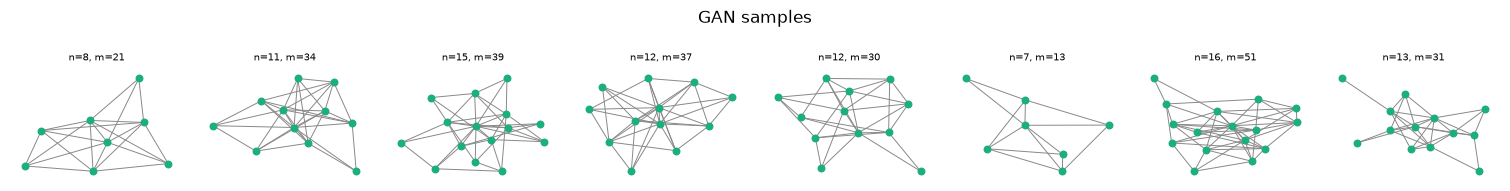

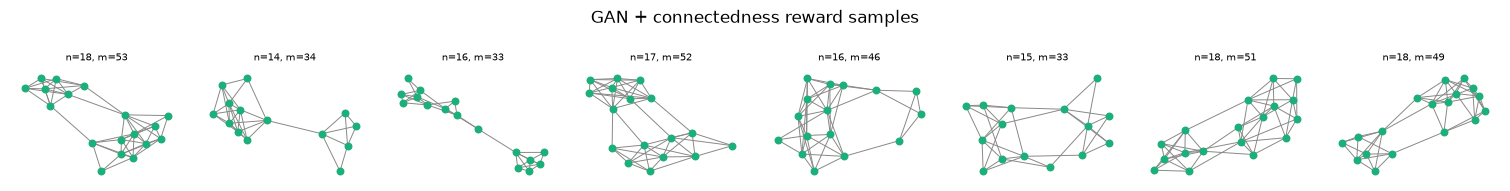

In [23]:
GAN_TRACKS = {}
for lam, name in [(0.0, 'GAN'), (0.5, 'GAN + reward')]:
    t0 = time.time()
    gen, GAN_TRACKS[name] = train_gan(train_graphs, reward_weight=lam)
    SAMPLES[name] = sample_gan(gen, NUM_SAMPLES)
    TIMES[name] = time.time() - t0
    print(f'{name} (λ = {lam}): ' + ' | '.join(f'step {s}: unique {u:.0%}, connected {c:.0%}' for s, u, c in GAN_TRACKS[name]))
for name in ['GAN', 'GAN + reward']:
    evaluate(name, SAMPLES[name], TIMES[name])
draw_graphs(SAMPLES['GAN'][:8], 'GAN samples', color=COLORS['GAN'])
draw_graphs(SAMPLES['GAN + reward'][:8], 'GAN + connectedness reward samples', color=COLORS['GAN'])

# 7. GraphAF

GraphAF combines two ideas: it generates the graph step by step like GraphRNN, but every step is a normalizing flow which gives the exact likelihood and allows parallel training.

## 7.1. Normalizing flows in one dimension

A flow is an invertible map $x = f_\theta(z)$ from a simple base variable $z\sim p_Z = \mathcal N(0, 1)$ to the data. The density of $x$ follows from the change-of-variables formula:

$$p_X(x) = p_Z\big(f_\theta^{-1}(x)\big)\,\left|\det\frac{\partial f_\theta^{-1}(x)}{\partial x}\right|.$$

GraphAF uses the simplest flow, an affine map $x = \alpha\,z + \mu$. Its inverse is $z = (x - \mu)/\alpha$ and the Jacobian term is $1/\alpha$, so $\log p_X(x) = \log\mathcal N\big((x-\mu)/\alpha\big) - \log\alpha$. We fit $\mu$ and $\alpha$ to 1-D data by maximum likelihood and check that the density integrates to 1. 

In [24]:
set_seed(0)
x_data = 3.0 + 0.5 * torch.randn(2000)                       # toy data: N(3, 0.5^2)
mu_1d = nn.Parameter(torch.zeros(1))
log_alpha_1d = nn.Parameter(torch.zeros(1))
opt = torch.optim.Adam([mu_1d, log_alpha_1d], lr=0.05)

def log_prob_1d(x, use_jacobian=True):
    z = (x - mu_1d) / log_alpha_1d.exp()                      # inverse flow f^{-1}(x)
    log_pz = -0.5 * z ** 2 - 0.5 * math.log(2 * math.pi)      # log N(z; 0, 1)
    return log_pz - log_alpha_1d if use_jacobian else log_pz # ★ KEY: + log |d f^{-1} / dx| = - log α

for step in range(500):
    loss = -log_prob_1d(x_data).mean()                        # maximum likelihood
    opt.zero_grad(); loss.backward(); opt.step()

grid = torch.linspace(-2, 8, 5001)
with torch.no_grad():
    for jac in [True, False]:
        integral = (log_prob_1d(grid, jac).exp() * (grid[1] - grid[0])).sum().item()
        print(f'with Jacobian term = {jac!s:<5}: ∫ p(x) dx = {integral:.3f}')
print(f'learned μ = {mu_1d.item():.3f}, α = {log_alpha_1d.exp().item():.3f} (data: mean {x_data.mean():.3f}, std {x_data.std():.3f})')

with Jacobian term = True : ∫ p(x) dx = 1.000
with Jacobian term = False: ∫ p(x) dx = 0.511
learned μ = 3.008, α = 0.511 (data: mean 3.008, std 0.511)


## 7.2. Graphs as a sequence of continuous variables

We reuse the BFS order and the bandwidth $M$ of GraphRNN: the pairs $(i, j)$ are generated in a fixed order node $i = 1, 2, \dots$, and for every node the pairs $j = i - M, \dots, i - 1$. GraphAF also generates node types; our nodes have no type, so we only generate edges, and we draw the number of nodes $n$ from the training graphs (as the diffusion models of Section 8 also do).

Dequantization: Flows need continuous data. The decision for pair $(i, j)$ is a one-hot vector $A_{ij}\in\{(1,0), (0,1)\}$ ("no edge", "edge"); we add uniform noise, $z_{A_{ij}} = A_{ij} + u$, $u\sim\mathcal U[0, 1)^2$. The argmax still recovers the discrete value.

Masking for parallel training: Step $t$ may only see the edges decided before it. For every step $t$ we precompute `CONTEXT_MASK[t]`, a $20\times20$ matrix with a 1 for every pair decided before step $t$. The context of all steps is then one product, `A * CONTEXT_MASK`, and all steps are trained **in one forward pass**.

187 generation steps (pairs) for a graph of 20 nodes with bandwidth M = 17


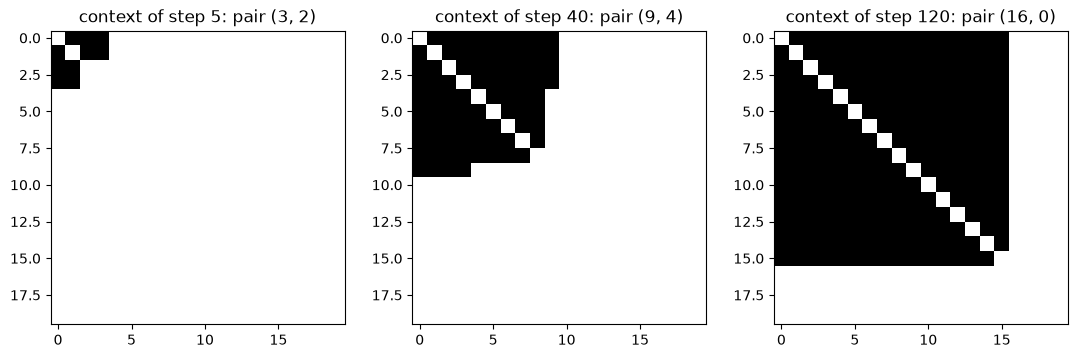

In [25]:
STEPS = [(i, j) for i in range(1, N_MAX) for j in range(max(0, i - M), i)]   # fixed generation order of the pairs
STEP_I = torch.tensor([i for i, _ in STEPS], device=device)
STEP_J = torch.tensor([j for _, j in STEPS], device=device)
T_STEPS = len(STEPS)

step_of_pair = torch.full((N_MAX, N_MAX), T_STEPS, device=device)       # step at which every pair is generated
step_of_pair[STEP_I, STEP_J] = torch.arange(T_STEPS, device=device)
step_of_pair[STEP_J, STEP_I] = torch.arange(T_STEPS, device=device)
# ★ KEY: CONTEXT_MASK[t, a, b] = 1 if pair (a, b) is generated before step t
CONTEXT_MASK = (step_of_pair[None] < torch.arange(T_STEPS, device=device)[:, None, None]).float()   # [T, N_MAX, N_MAX]
NODE_MASK = (torch.arange(N_MAX, device=device)[None] <= STEP_I[:, None]).float()                  # [T, N_MAX]: nodes 0..i exist
print(f'{T_STEPS} generation steps (pairs) for a graph of {N_MAX} nodes with bandwidth M = {M}')

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, t in zip(axes, [5, 40, 120]):
    ax.imshow(CONTEXT_MASK[t].cpu(), cmap='Greys')
    ax.set_title(f'context of step {t}: pair {STEPS[t]}')
plt.tight_layout()
plt.show()

def bfs_adjacency_batch(graph_list, rng):
    """Adjacency matrices in a fresh random BFS order (padded) and the number of nodes of every graph."""
    A = torch.zeros(len(graph_list), N_MAX, N_MAX)
    for b, G in enumerate(graph_list):
        n = G.number_of_nodes()
        A[b, :n, :n] = torch.tensor(nx.to_numpy_array(G, nodelist=bfs_order(G, rng)), dtype=torch.float)
    return A.to(device), torch.tensor([G.number_of_nodes() for G in graph_list], device=device)

## 7.3. The model

* Context: a GCN (GraphAF uses an R-GCN, which has one weight matrix per edge type; with one edge type it is a GCN) on the graph generated so far gives node embeddings $H$, and a sum gives the graph embedding $\tilde h = \mathrm{sum}(H)$.
* Flow parameters: an MLP gives $(\mu_{ij}, \log\alpha_{ij}) = \mathrm{MLP}(\tilde h, H_i, H_j)$. We also give the MLP the position $i/N_{max}$ and the distance $(i-j)/M$ in the BFS order (our nodes have no types, so this is the only way to tell the steps apart).
* Generation: $z_{ij} = \epsilon_{ij}\odot\alpha_{ij} + \mu_{ij}$, $\epsilon_{ij}\sim\mathcal N(0, I)$, then the edge is $\arg\max z_{ij}$.
* Training: the inverse $\epsilon_{ij} = (z_{ij} - \mu_{ij})\oslash\alpha_{ij}$ and the change of variables give the exact log-likelihood $\log p(z_{ij}) = \log\mathcal N(\epsilon_{ij}; 0, I) - \sum_d\log\alpha_{ij,d}$.

NLL per edge decision (nats): GraphAF train 1.361 | GraphAF test 1.354 | one Gaussian for all decisions (no context) 1.685
GraphAF    MMD deg 0.0749 | clus 0.3005 | spec 0.1054 | connected 99% | unique 100% | novel 100% | nodes 16.1 | edges 44.9 | time   64.7s


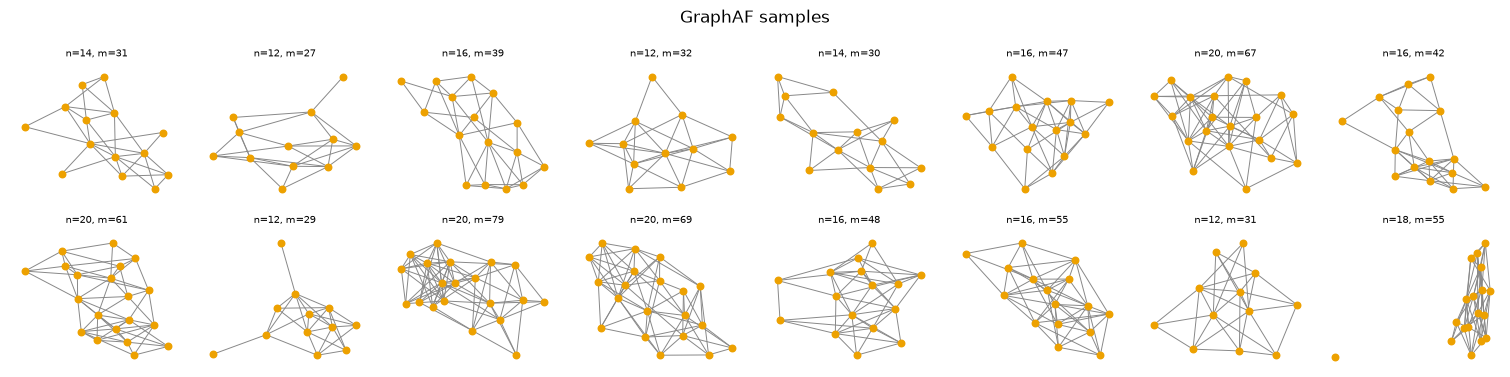

In [26]:
class GraphAF(nn.Module):
    """GCN context on the partial graph -> (mu, log alpha) of the affine flow of one pair (i, j)."""
    def __init__(self, hidden=64, layers=3):
        super().__init__()
        self.gcns = nn.ModuleList([DenseGCNLayer(1 if l == 0 else hidden, hidden) for l in range(layers)])
        self.edge_mlp = nn.Sequential(nn.Linear(3 * hidden + 2, 2 * hidden), nn.ReLU(), nn.Linear(2 * hidden, 4))

    def flow_params(self, A_ctx, node_mask, i, j):
        H = node_mask[..., None]                                       # every existing node starts with feature 1
        for gcn in self.gcns:
            H = F.relu(gcn(H, A_ctx, node_mask))                       # ★ KEY: H = R-GCN(G_i)
        h_graph = H.sum(dim=1)                                         # ★ KEY: h~ = sum(H)
        rows = torch.arange(H.size(0), device=H.device)
        position = torch.stack([i / N_MAX, (i - j) / M], dim=-1).float()
        out = self.edge_mlp(torch.cat([h_graph, H[rows, i], H[rows, j], position], dim=-1))
        mu, log_alpha = out[:, :2], 3 * torch.tanh(out[:, 2:] / 3)    # keep log α in (-3, 3) for stability
        return mu, log_alpha

def graphaf_nll(model, A, n_nodes):
    """Mean negative log-likelihood of one (dequantized) edge decision, all steps of all graphs in parallel."""
    B = A.size(0)
    x = A[:, STEP_I, STEP_J]                                           # [B, T] the true decisions
    z = F.one_hot(x.long(), 2).float() + torch.rand(B, T_STEPS, 2, device=device)   # ★ KEY: dequantization
    A_ctx = (A[:, None] * CONTEXT_MASK[None]).reshape(B * T_STEPS, N_MAX, N_MAX)      # ★ KEY: masked contexts
    node_mask = NODE_MASK[None].expand(B, -1, -1).reshape(B * T_STEPS, N_MAX)
    mu, log_alpha = model.flow_params(A_ctx, node_mask, STEP_I.repeat(B), STEP_J.repeat(B))
    eps = (z.reshape(B * T_STEPS, 2) - mu) * torch.exp(-log_alpha)    # ★ KEY: inverse flow
    log_p = (-0.5 * eps ** 2 - 0.5 * math.log(2 * math.pi)).sum(-1) - log_alpha.sum(-1)   # change of variables
    valid = (STEP_I[None] < n_nodes[:, None]).float().reshape(-1)     # steps that exist in the graph
    return -(log_p * valid).sum() / valid.sum()

def train_graphaf(graph_list, epochs=300, batch_size=32, lr=0.001, seed=0):
    set_seed(seed)
    rng = np.random.default_rng(seed)
    model = GraphAF().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        perm, total = rng.permutation(len(graph_list)), 0.0
        for start in range(0, len(graph_list), batch_size):
            A, n_nodes = bfs_adjacency_batch([graph_list[k] for k in perm[start:start + batch_size]], rng)
            loss = graphaf_nll(model, A, n_nodes)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item()
        losses.append(total / math.ceil(len(graph_list) / batch_size))
    return model, losses

@torch.no_grad()
def sample_graphaf(model, num, temperature=1.0, seed=0):
    """Sequential generation: sample eps, z = eps * alpha + mu, edge = argmax z, update the context."""
    rng = np.random.default_rng(seed)
    n_nodes = torch.tensor(rng.choice(n_nodes_train, num), device=device)
    A = torch.zeros(num, N_MAX, N_MAX, device=device)
    for t, (i, j) in enumerate(STEPS):
        mu, log_alpha = model.flow_params(A, NODE_MASK[t].expand(num, -1),
                                          torch.full((num,), i, device=device), torch.full((num,), j, device=device))
        eps = temperature * torch.randn(num, 2, device=device)
        z = eps * log_alpha.exp() + mu                                 # ★ KEY: forward flow
        edge = (z.argmax(-1) == 1) & (i < n_nodes)                     # back to a discrete decision
        A[:, i, j] = A[:, j, i] = edge.float()
    return [adj_to_nx(A[b, :n, :n]) for b, n in enumerate(n_nodes.tolist())]

t0 = time.time()
graphaf, af_losses = train_graphaf(train_graphs)
SAMPLES['GraphAF'] = sample_graphaf(graphaf, NUM_SAMPLES)
TIMES['GraphAF'] = time.time() - t0

# Exact NLL of the test graphs, and a baseline flow without graph context: ONE Gaussian for every decision
rng = np.random.default_rng(1)
A_eval, n_eval = bfs_adjacency_batch(test_graphs, rng)
with torch.no_grad():
    nll_test = np.mean([graphaf_nll(graphaf, A_eval, n_eval).item() for _ in range(5)])
valid = STEP_I[None] < n_eval[:, None]
z = F.one_hot(A_eval[:, STEP_I, STEP_J][valid].long(), 2).float()
z = z + torch.rand_like(z)                                              # dequantized test decisions
nll_base = (0.5 * torch.log(2 * math.pi * z.var(0)) + 0.5).sum().item()   # NLL of the best single Gaussian
print(f'NLL per edge decision (nats): GraphAF train {af_losses[-1]:.3f} | GraphAF test {nll_test:.3f} | '
      f'one Gaussian for all decisions (no context) {nll_base:.3f}')
evaluate('GraphAF', SAMPLES['GraphAF'], TIMES['GraphAF'])
draw_graphs(SAMPLES['GraphAF'][:16], 'GraphAF samples', color=COLORS['GraphAF'])

# 8. Diffusion models

A diffusion model gradually corrupts the data into pure noise with a fixed process, then trains a network to reverse it one small step at a time. Generating means starting from noise and running the learned reverse process. We study the two graph diffusion models of the lecture:

| | EDP-GNN | DiGress |
|:--|:--|:--|
| Noise | continuous: Gaussian noise added to $\mathbf A$ | discrete: random edge flips (Markov transition matrices) |
| The network predicts | the score $\nabla_{\tilde{\mathbf A}}\log q_\sigma(\tilde{\mathbf A})$ | the clean graph (one classification per pair) |
| Sampling | annealed Langevin dynamics, then rounding | the closed-form posterior, step by step |

Both need a network that outputs one value per node pair and is permutation equivariant EDP-GNN keeps edge-wise features (a multi-channel adjacency matrix) and updates them layer by layer (edgewise dense prediction). We use a small network in this spirit:
1. every pair $(i, j)$ starts with a feature vector computed from $[\tilde A_{ij},\, \mathbb 1_{i=j}]$, plus an embedding of the noise level;
2. every layer combines pairs along paths of length 2 for every channel, $\mathrm{paths}_{ij} = \frac1n\sum_k L(E_{ik})\,R(E_{kj})$ (a matrix product), then $E_{ij}\leftarrow E_{ij} + \mathrm{MLP}([E_{ij}, \mathrm{paths}_{ij}])$;
3. a final MLP gives one number per pair, averaged with its transpose so that the output is symmetric

Why paths? All our nodes look alike (same degree range, no features). A message-passing GNN computes almost the same embedding for every node (the 1-WL limit of message passing), so an output built from node embeddings cannot tell whether $i$ and $j$ are in the same community. Paths can: two nodes of the same community share many neighbours, and the first layer already sees $(\tilde{\mathbf A}^2)_{ij}$, the number of common neighbours. With $\ell$ layers the features see paths of length up to $2^\ell$. Every operation (matrix products, pairwise MLPs) commutes with relabelling the nodes, so the network is equivariant.

In [27]:
class EdgeNet(nn.Module):
    """Edge-wise, permutation-equivariant network: noisy adjacency A [B, n, n] + noise level c [B] -> one value per pair."""
    def __init__(self, hidden=32, layers=4):
        super().__init__()
        self.inp = nn.Linear(2, hidden)                                            # [A_ij, 1 if i = j]
        self.cond = nn.Sequential(nn.Linear(1, hidden), nn.ReLU(), nn.Linear(hidden, hidden))   # noise level embedding
        self.left = nn.ModuleList([nn.Linear(hidden, hidden) for _ in range(layers)])
        self.right = nn.ModuleList([nn.Linear(hidden, hidden) for _ in range(layers)])
        self.update = nn.ModuleList([nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden))
                                     for _ in range(layers)])
        self.out = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, A, mask, c):
        n = mask.sum(1).clamp(min=1)[:, None, None, None]                          # number of nodes of every graph
        real = (mask[:, :, None] * mask[:, None, :])[..., None]                    # pairs of real nodes (diagonal included)
        eye = torch.eye(A.size(1), device=A.device).expand_as(A)
        E = (self.inp(torch.stack([A, eye], dim=-1)) + self.cond(c[:, None].float())[:, None, None]) * real   # [B, n, n, d]
        for left, right, update in zip(self.left, self.right, self.update):
            L = left(E).permute(0, 3, 1, 2)                                        # [B, d, n, n]: one matrix per channel
            R = right(E).permute(0, 3, 1, 2)
            paths = (L @ R).permute(0, 2, 3, 1) / n                                # ★ KEY: Σ_k L(E_ik) R(E_kj), paths i -> k -> j
            E = (E + update(torch.cat([E, paths], dim=-1))) * real
        out = self.out(E).squeeze(-1)
        return (out + out.transpose(1, 2)) / 2 * pair_mask(mask)                  # symmetric, 0 on the diagonal and padding

def pair_mask(mask):
    """1 for the pairs (i, j), i != j, of two real nodes."""
    eye = torch.eye(mask.size(1), device=mask.device)
    return mask[:, :, None] * mask[:, None, :] * (1 - eye)

def symmetric_noise(mask):
    """Symmetric standard Gaussian noise on the real pairs (zero diagonal and padding)."""
    upper = torch.triu(torch.randn(mask.size(0), mask.size(1), mask.size(1), device=mask.device), diagonal=1)
    return (upper + upper.transpose(1, 2)) * pair_mask(mask)

def random_masks(num, seed=0):
    """Node masks with a number of nodes drawn from the training graphs."""
    n = np.random.default_rng(seed).choice(n_nodes_train, num)
    return (torch.arange(N_MAX)[None] < torch.tensor(n)[:, None]).float().to(device)

def masked_to_graphs(A, mask):
    return [adj_to_nx(A[b], mask[b]) for b in range(A.size(0))]

## 8.1. The forward process: Gaussian vs. discrete noise

Gaussian noise (EDP-GNN): $\tilde{\mathbf A} = \mathbf A + \sigma\,\mathbf N$, with symmetric standard Gaussian noise $\mathbf N$, for a growing $\sigma$.

Discrete noise (DiGress). Every pair is a categorical variable with $d = 2$ classes (no edge / edge), written as a one-hot row vector $x$. One step of noise is a transition matrix $Q_t$, $[Q_t]_{ab} = P(\text{class } a \to \text{class } b)$:
$$q(z_t\mid z_{t-1}) = z_{t-1}Q_t,\qquad q(z_t\mid x) = x\,\bar Q_t,\quad \bar Q_t = Q_1Q_2\cdots Q_t .$$
DiGress uses the marginal transition: with probability $\alpha_t$ keep the class, otherwise draw a new class from the marginal distribution $m = (1-\rho, \rho)$ of the data ($\rho$ = edge density):
$$Q_t = \alpha_t I + (1-\alpha_t)\,\mathbf 1 m^\top,\qquad \bar Q_t = \bar\alpha_t I + (1-\bar\alpha_t)\,\mathbf 1 m^\top,\quad \bar\alpha_t = \prod_{s\le t}\alpha_s .$$
The closed form of $\bar Q_t$ allows us to noise a graph to any step $t$ in one shot. When $\bar\alpha_T\to 0$, $q(z_T\mid x)\to m$ does not depend on $x$ (property 3): we can start sampling from $m$. We use $T = 100$ steps and the cosine schedule of DiGress for $\bar\alpha_t$.

In [28]:
SIGMAS = torch.tensor([1.6, 0.8, 0.6, 0.4, 0.2, 0.1], device=device)   # EDP-GNN noise levels, large -> small

T_DIFF = 100
s = 0.008
f = torch.cos((torch.arange(T_DIFF + 1, device=device) / T_DIFF + s) / (1 + s) * math.pi / 2) ** 2
ALPHA_BAR = (f / f[0]).clamp(min=1e-6)                            # ᾱ_0 = 1, ..., ᾱ_T ≈ 0 (cosine schedule)
ALPHA = torch.ones_like(ALPHA_BAR)
ALPHA[1:] = ALPHA_BAR[1:] / ALPHA_BAR[:-1]                        # α_t = ᾱ_t / ᾱ_{t-1}

A_train, mask_train = pad_batch(train_graphs)
RHO = (A_train.sum() / pair_mask(mask_train).sum()).item()        # edge density = marginal of the class "edge"
MARGINAL = torch.tensor([1 - RHO, RHO], device=device)

def Q(t, m=MARGINAL):
    """One-step transition matrix Q_t = α_t I + (1 - α_t) 1 m^T. t: an int (-> [2, 2]) or a tensor [B] (-> [B, 2, 2])."""
    a = ALPHA[t][..., None, None]
    return a * torch.eye(2, device=device) + (1 - a) * m[None, :]       # every row of 1 m^T is m

def Q_bar(t, m=MARGINAL):
    """Cumulative transition matrix Q̄_t = ᾱ_t I + (1 - ᾱ_t) 1 m^T (closed form of Q_1 Q_2 ... Q_t)."""
    a = ALPHA_BAR[t][..., None, None]
    return a * torch.eye(2, device=device) + (1 - a) * m[None, :]

product = torch.eye(2, device=device)
for t in range(1, T_DIFF + 1):
    product = product @ Q(t)
print(f'edge density rho = {RHO:.3f} | ᾱ_T = {ALPHA_BAR[-1]:.1e}')
print(f'max |Q_1 Q_2 ... Q_T - Q̄_T| = {(product - Q_bar(T_DIFF)).abs().max():.1e}')
print('Q̄_T =', Q_bar(T_DIFF).cpu().double().numpy().round(3).tolist(), '(both rows = m: the limit does not depend on x)')

def noisy_edges(A, mask, t, m=MARGINAL):
    """Sample z_t ~ q(z_t | x) = x Q̄_t for every pair; t = one time step per graph (list or tensor [B])."""
    onehot = F.one_hot(A.long(), 2).float()                            # [B, n, n, 2]
    Qb = Q_bar(torch.as_tensor(t, device=device), m)                   # [B, 2, 2]
    probs = onehot @ Qb[:, None]                                       # ★ KEY: x Q̄_t   [B, n, n, 2]
    return sample_symmetric(probs[..., 1] * pair_mask(mask))

edge density rho = 0.354 | ᾱ_T = 1.0e-06
max |Q_1 Q_2 ... Q_T - Q̄_T| = 1.2e-07
Q̄_T = [[0.646, 0.354], [0.646, 0.354]] (both rows = m: the limit does not depend on x)


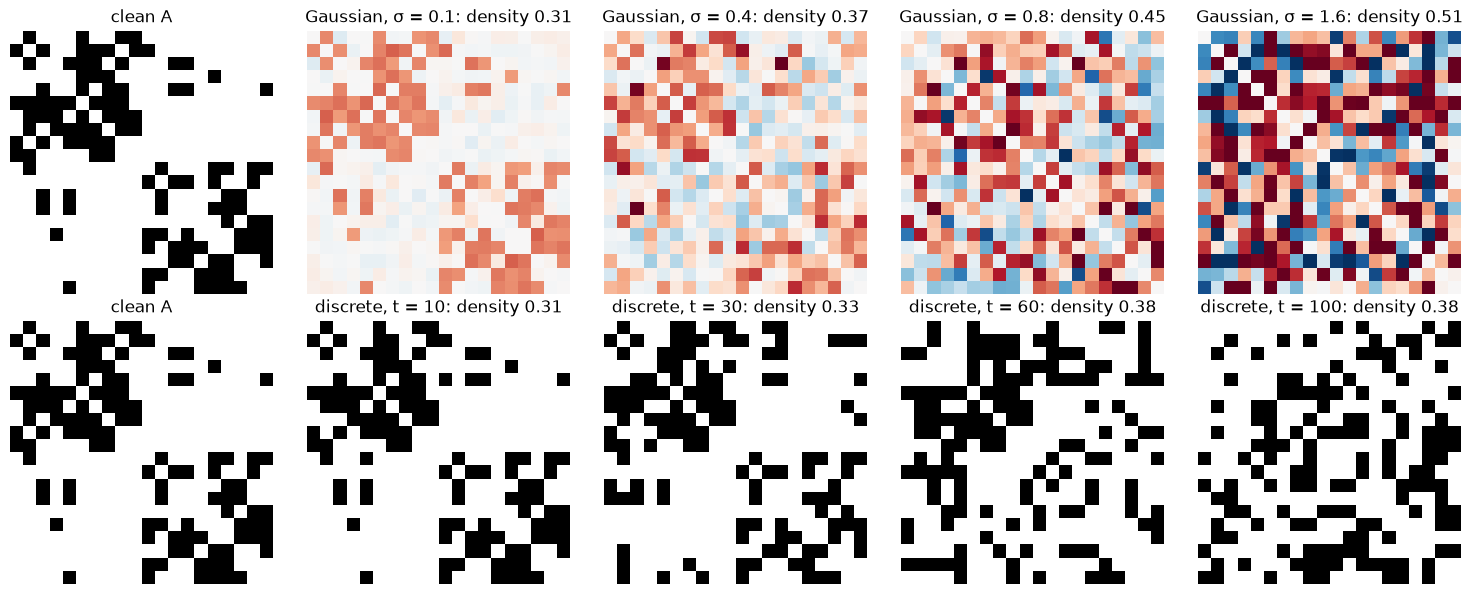

Gaussian σ = 0.1: density of (Ã > 0.5) = 0.354
Gaussian σ = 0.2: density of (Ã > 0.5) = 0.356
Gaussian σ = 0.4: density of (Ã > 0.5) = 0.384
Gaussian σ = 0.6: density of (Ã > 0.5) = 0.413
Gaussian σ = 0.8: density of (Ã > 0.5) = 0.433
Gaussian σ = 1.6: density of (Ã > 0.5) = 0.464
Discrete t =   0: density of z_t = 0.354
Discrete t =  25: density of z_t = 0.353
Discrete t =  50: density of z_t = 0.353
Discrete t =  75: density of z_t = 0.356
Discrete t = 100: density of z_t = 0.354


In [29]:
G0 = train_graphs[0]
S1, S2 = nx.algorithms.community.kernighan_lin_bisection(G0, seed=0)
order0 = sorted(S1) + sorted(S2)                                  # list the two communities one after the other (for the picture)
A0, mask0 = pad_batch([nx.relabel_nodes(G0, {v: k for k, v in enumerate(order0)})])
set_seed(0)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes[0, 0].imshow(A0[0].cpu(), cmap='Greys'); axes[0, 0].set_title('clean A')
axes[1, 0].imshow(A0[0].cpu(), cmap='Greys'); axes[1, 0].set_title('clean A')
for col, sigma in enumerate([0.1, 0.4, 0.8, 1.6], start=1):
    A_noisy = A0 + sigma * symmetric_noise(mask0)
    dens = ((A_noisy > 0.5).float() * pair_mask(mask0)).sum() / pair_mask(mask0).sum()
    axes[0, col].imshow(A_noisy[0].cpu(), cmap='RdBu_r', vmin=-2, vmax=2)
    axes[0, col].set_title(f'Gaussian, σ = {sigma}: density {dens:.2f}')
for col, t in enumerate([10, 30, 60, 100], start=1):
    E_t = noisy_edges(A0, mask0, [t])
    dens = E_t.sum() / pair_mask(mask0).sum()
    axes[1, col].imshow(E_t[0].cpu(), cmap='Greys')
    axes[1, col].set_title(f'discrete, t = {t}: density {dens:.2f}')
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

# Edge density of the noisy training graphs (after rounding at 0.5 for the Gaussian case)
pm = pair_mask(mask_train)
for sigma in SIGMAS.flip(0).tolist():
    print(f'Gaussian σ = {sigma:.1f}: density of (Ã > 0.5) = {(((A_train + sigma * symmetric_noise(mask_train)) > 0.5).float() * pm).sum() / pm.sum():.3f}')
for t in [0, 25, 50, 75, 100]:
    print(f'Discrete t = {t:>3}: density of z_t = {noisy_edges(A_train, mask_train, [t] * len(train_graphs)).sum() / pm.sum():.3f}')

* The closed form $\bar Q_t$ equals the product of the 100 one-step matrices (up to rounding), and at $t = T$ both rows of $\bar Q_T$ equal $m$: noisy graphs no longer depend on the data.
* Gaussian noise destroys sparsity: with $\sigma = 1.6$, rounding the noisy matrix gives a graph with density close to 0.5, a dense random graph whose cycles and connectivity have nothing to do with the data.
* Marginal discrete noise keeps the density at $\rho\approx 0.36$ at every step: noisy graphs are real, sparse graphs, and only the structure (the two communities) is gradually destroyed. Structural features of the noisy graph (degrees, cycles) stay meaningful, which DiGress exploits.

## 8.2. EDP-GNN: score-based generation

Score: Instead of the density $p(\mathbf A)$, EDP-GNN learns its score the gradient $\nabla_{\mathbf A}\log p(\mathbf A)$: the direction in which the log-density increases. The score needs no normalisation constant, so any network can model it. Perturbing the data with Gaussian noise of level $\sigma$ gives $q_\sigma(\tilde{\mathbf A}\mid\mathbf A) = \mathcal N(\mathbf A, \sigma^2 I)$, whose score is known: $\nabla_{\tilde{\mathbf A}}\log q_\sigma(\tilde{\mathbf A}\mid\mathbf A) = -(\tilde{\mathbf A}-\mathbf A)/\sigma^2$. The network $s_\theta(\tilde{\mathbf A}, \sigma)$ is trained to match it at $L = 6$ noise levels (denoising score matching):
$$\frac1L\sum_{i=1}^{L}\sigma_i^2\;\mathbb E\Big\|s_\theta(\tilde{\mathbf A}, \sigma_i) - \nabla_{\tilde{\mathbf A}}\log q_{\sigma_i}(\tilde{\mathbf A}\mid\mathbf A)\Big\|_2^2 .$$
We parameterise $s_\theta = \mathrm{EdgeNet}(\tilde{\mathbf A}, \sigma)/\sigma$, a common choice that keeps the network output of order 1 at every noise level.

Sampling with annealed Langevin dynamics: from the largest to the smallest $\sigma_i$, repeat $\tilde{\mathbf A}\leftarrow\tilde{\mathbf A} + \frac{\alpha_i}{2}s_\theta(\tilde{\mathbf A}, \sigma_i) + \sqrt{\alpha_i}\,\mathbf N$ with the step size $\alpha_i = \epsilon\,\sigma_i^2/\sigma_L^2$. Finally, quantise $A_{ij} = \mathbb 1[\tilde A_{ij} > 0.5]$. The number of nodes is drawn from the training graphs.

score-matching loss: first epoch 0.652 -> last epoch 0.159
EDP-GNN    MMD deg 0.0147 | clus 0.1052 | spec 0.0329 | connected 98% | unique 100% | novel 100% | nodes 16.1 | edges 42.7 | time  109.7s


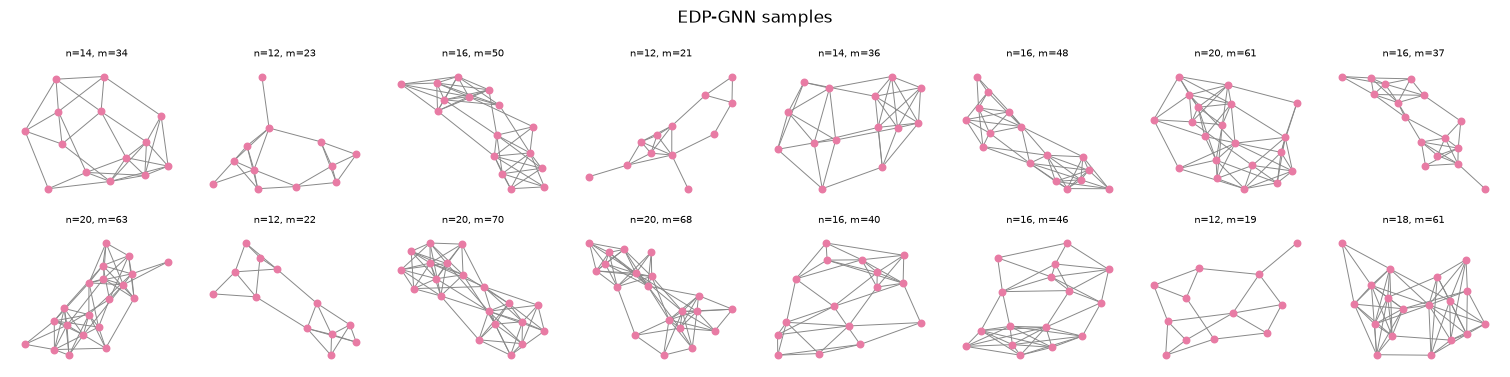

In [30]:
def edp_loss(model, A, mask):
    sigma = SIGMAS[torch.randint(len(SIGMAS), (A.size(0),), device=device)][:, None, None]   # one level per graph
    noise = symmetric_noise(mask)
    A_noisy = A + sigma * noise                                        # perturbed adjacency
    score = model(A_noisy, mask, sigma.view(-1)) / sigma               # s_θ(Ã, σ)
    target = -(A_noisy - A) / sigma ** 2                               # ★ KEY: ∇ log q_σ(Ã | A) = -(Ã - A) / σ²
    pm = pair_mask(mask)
    return ((sigma ** 2 * (score - target) ** 2) * pm).sum() / pm.sum()   # ★ KEY: denoising score matching

def train_diffusion(loss_fn, graph_list, epochs=500, batch_size=32, lr=0.001, seed=0, **net_args):
    set_seed(seed)
    model = EdgeNet(**net_args).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    A_all, mask_all = pad_batch(graph_list)
    losses = []
    for epoch in range(epochs):
        perm, total = torch.randperm(len(graph_list)), 0.0
        for start in range(0, len(graph_list), batch_size):
            idx = perm[start:start + batch_size]
            loss = loss_fn(model, A_all[idx], mask_all[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item()
        losses.append(total / math.ceil(len(graph_list) / batch_size))
    return model, losses

@torch.no_grad()
def sample_edp(model, num, steps_per_level=50, step_size=0.002, seed=0):
    mask = random_masks(num, seed)
    A = SIGMAS[0] * symmetric_noise(mask)                              # start from pure noise
    for sigma in SIGMAS:                                               # large -> small noise
        alpha = step_size * (sigma / SIGMAS[-1]) ** 2
        for _ in range(steps_per_level):
            score = model(A, mask, sigma.expand(num)) / sigma
            A = A + 0.5 * alpha * score + torch.sqrt(alpha) * symmetric_noise(mask)   # ★ KEY: Langevin step
    return masked_to_graphs((A > 0.5).float() * pair_mask(mask), mask)               # ★ KEY: quantisation

t0 = time.time()
edp, edp_losses = train_diffusion(edp_loss, train_graphs)
SAMPLES['EDP-GNN'] = sample_edp(edp, NUM_SAMPLES)
TIMES['EDP-GNN'] = time.time() - t0
print(f'score-matching loss: first epoch {edp_losses[0]:.3f} -> last epoch {edp_losses[-1]:.3f}')
evaluate('EDP-GNN', SAMPLES['EDP-GNN'], TIMES['EDP-GNN'])
draw_graphs(SAMPLES['EDP-GNN'][:16], 'EDP-GNN samples', color=COLORS['EDP-GNN'])

Permutation equivariance: If the score network is equivariant, $s_\theta(\mathbf P\tilde{\mathbf A}\mathbf P^\top) = \mathbf P\,s_\theta(\tilde{\mathbf A})\,\mathbf P^\top$, the distribution it defines gives the same probability to every ordering of a graph. We check it on a noisy graph.

In [31]:
A1, m1 = pad_batch(train_graphs[:1])
n1 = int(m1.sum())
P = torch.eye(N_MAX, device=device)
P[:n1, :n1] = torch.eye(n1, device=device)[torch.randperm(n1)]       # permute the real nodes only
A_noisy = A1 + 0.4 * symmetric_noise(m1)
sigma = torch.tensor([0.4], device=device)
with torch.no_grad():
    out = edp(A_noisy, m1, sigma)[0]
    out_perm = edp((P @ A_noisy[0] @ P.T)[None], m1, sigma)[0]
print(f'max |s(P Ã P^T) - P s(Ã) P^T| = {(out_perm - P @ out @ P.T).abs().max():.1e}')

max |s(P Ã P^T) - P s(Ã) P^T| = 4.8e-07


## 8.3. DiGress: discrete denoising diffusion

DiGress noises the graph with the discrete process of Section 8.1 and trains the network to predict the clean graph $x$ from the noisy graph $z_t$: one classification per pair, "edge or not", with a cross-entropy loss. DiGress uses a graph transformer and also predicts node and edge types; we use the `EdgeNet` above and edges only.

Sampling: The posterior of one step given the clean graph has a closed form (Bayes' rule):
$$q(z_{t-1}\mid z_t, x)\;\propto\; z_t Q_t^\top\odot x\bar Q_{t-1}.$$
The first factor is the probability of the observed $z_t$ coming from every possible $z_{t-1}$, the second the probability of every $z_{t-1}$ given $x$. We do not know $x$, so we average over the network's prediction $\hat p_\theta(x\mid z_t)$:
$$p_\theta(z_{t-1}\mid z_t) = \sum_{x} \hat p_\theta(x\mid z_t)\; q(z_{t-1}\mid z_t, x).$$
We start from $z_T\sim m$ (every pair is an edge with probability $\rho$) and apply this step $T = 100$ times.

denoising cross-entropy: first epoch 0.676 -> last epoch 0.397
DiGress    MMD deg 0.0173 | clus 0.0331 | spec 0.0166 | connected 96% | unique 100% | novel 100% | nodes 16.1 | edges 43.0 | time  109.0s


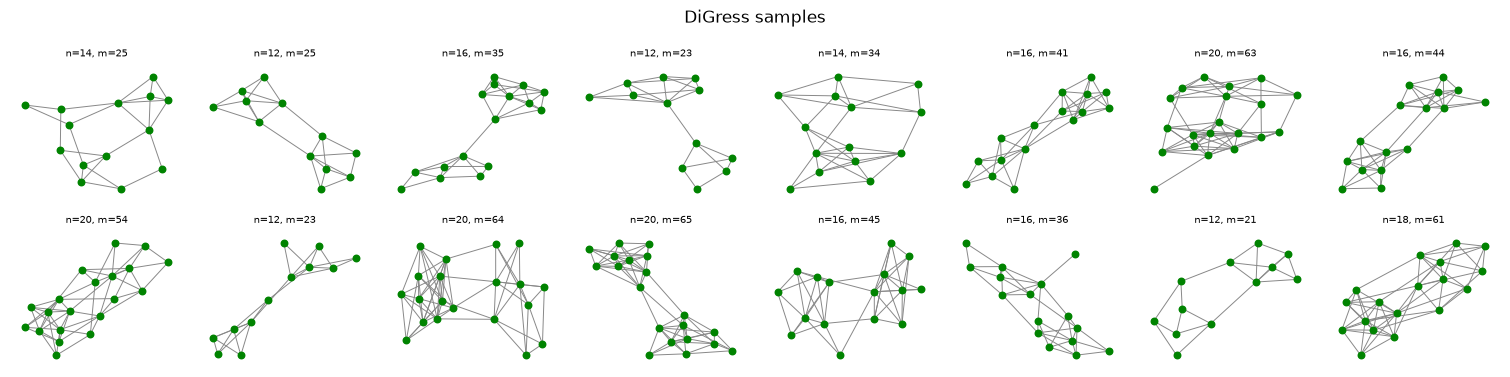

In [32]:
def digress_loss(model, A, mask):
    t = torch.randint(1, T_DIFF + 1, (A.size(0),), device=device)     # a random time step per graph
    E_t = noisy_edges(A, mask, t)                                      # z_t ~ x Q̄_t
    logits = model(E_t, mask, t / T_DIFF)                              # predicts the clean graph x
    pm = torch.triu(pair_mask(mask), diagonal=1)                       # every pair once
    bce = F.binary_cross_entropy_with_logits(logits, A, reduction='none')   # ★ KEY: classification of every pair
    return (bce * pm).sum() / pm.sum()

def posterior_step(E_t, p_edge, t, m=MARGINAL):
    """Probability that every pair is an edge at step t-1: Σ_x p(x | z_t) q(z_{t-1} | z_t, x)."""
    z_t = F.one_hot(E_t.long(), 2).float()                             # [B, n, n, 2]
    left = z_t @ Q(t, m).T                                             # z_t Q_t^T: q(z_t | z_{t-1} = c) for every c
    post = left[..., None, :] * Q_bar(t - 1, m)                        # ★ KEY: z_t Q_t^T ⊙ x Q̄_{t-1}   [B, n, n, x, c]
    post = post / post.sum(-1, keepdim=True).clamp(min=1e-12)          # normalise over c
    p_x = torch.stack([1 - p_edge, p_edge], dim=-1)                    # p̂(x | z_t)   [B, n, n, 2]
    return (p_x[..., None] * post).sum(-2)[..., 1]                     # ★ KEY: average over x

@torch.no_grad()
def sample_digress(model, num, seed=0, m=MARGINAL):
    mask = random_masks(num, seed)
    E = sample_symmetric(m[1] * pair_mask(mask))                       # ★ KEY: z_T ~ m (the limit distribution)
    for t in range(T_DIFF, 0, -1):
        p_edge = torch.sigmoid(model(E, mask, torch.full((num,), t / T_DIFF, device=device)))
        E = sample_symmetric(posterior_step(E, p_edge, t, m) * pair_mask(mask))
    return masked_to_graphs(E, mask)

t0 = time.time()
digress, dig_losses = train_diffusion(digress_loss, train_graphs)
SAMPLES['DiGress'] = sample_digress(digress, NUM_SAMPLES)
TIMES['DiGress'] = time.time() - t0
print(f'denoising cross-entropy: first epoch {dig_losses[0]:.3f} -> last epoch {dig_losses[-1]:.3f}')
evaluate('DiGress', SAMPLES['DiGress'], TIMES['DiGress'])
draw_graphs(SAMPLES['DiGress'][:16], 'DiGress samples', color=COLORS['DiGress'])

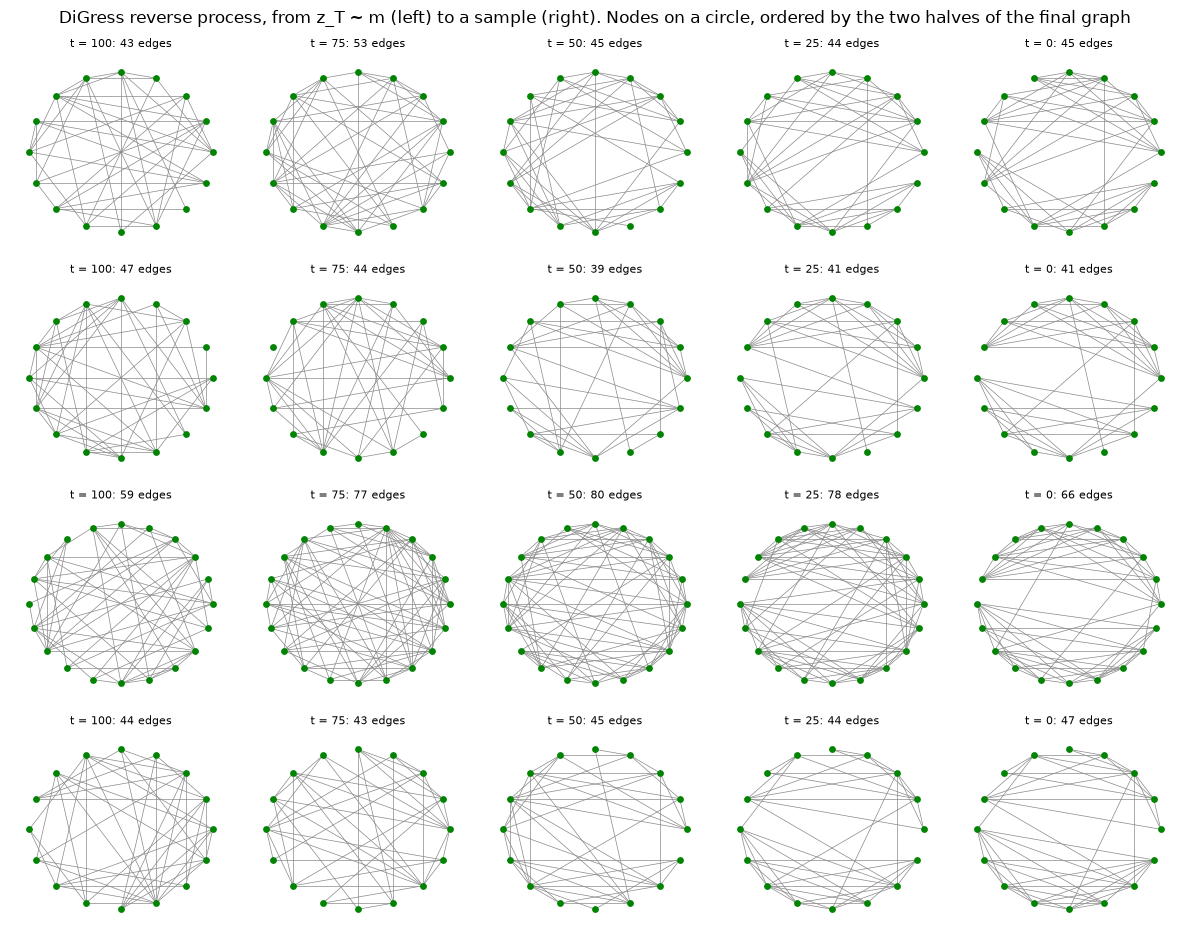

In [33]:
# The reverse process of DiGress for 4 samples: noisy graph z_t at a few time steps
set_seed(1)
mask = random_masks(4, seed=1)
E = sample_symmetric(MARGINAL[1] * pair_mask(mask))
snapshots = {T_DIFF: E.clone()}
with torch.no_grad():
    for t in range(T_DIFF, 0, -1):
        p_edge = torch.sigmoid(digress(E, mask, torch.full((4,), t / T_DIFF, device=device)))
        E = sample_symmetric(posterior_step(E, p_edge, t) * pair_mask(mask))
        if t - 1 in [75, 50, 25, 0]:
            snapshots[t - 1] = E.clone()
fig, axes = plt.subplots(4, 5, figsize=(12, 9.5))
for row in range(4):
    final = adj_to_nx(snapshots[0][row], mask[row])
    S1, S2 = nx.algorithms.community.kernighan_lin_bisection(final, seed=0)
    circle = sorted(S1) + sorted(S2)                                         # the two halves of the final graph
    pos = {v: (np.cos(2 * np.pi * k / len(circle)), np.sin(2 * np.pi * k / len(circle))) for k, v in enumerate(circle)}
    for col, t in enumerate(sorted(snapshots, reverse=True)):
        G = adj_to_nx(snapshots[t][row], mask[row])
        nx.draw(G, pos, ax=axes[row, col], node_size=15, node_color=COLORS['DiGress'], width=0.5, edge_color='#888888')
        axes[row, col].set_title(f't = {t}: {G.number_of_edges()} edges', fontsize=8)
plt.suptitle('DiGress reverse process, from z_T ~ m (left) to a sample (right). Nodes on a circle, '
             'ordered by the two halves of the final graph')
plt.tight_layout()
plt.show()

# 9. Summary: all models side by side

Every model was trained on the same 400 graphs and generated 200 graphs, scored against the same 200 test graphs. The time column is training + sampling on this machine.

In [34]:
ORDER = ['Data', 'ER', 'BA', 'SBM', 'GraphRNN', 'GraphVAE (no matching)', 'GraphVAE', 'GraphVAE (agg. posterior)',
         'GAN', 'GAN + reward', 'GraphAF', 'EDP-GNN', 'DiGress']
print(f"{'model':<26}{'MMD deg':>9}{'MMD clus':>10}{'MMD spec':>10}{'connected':>11}{'unique':>8}{'novel':>7}{'time':>8}")
for name in ORDER:
    r = RESULTS[name]
    t = f"{r['time']:.0f}s" if r['time'] is not None else '-'
    print(f"{name:<26}{r['deg']:>9.4f}{r['clus']:>10.4f}{r['spec']:>10.4f}{r['connected']:>11.0%}{r['unique']:>8.0%}{r['novel']:>7.0%}{t:>8}")

model                       MMD deg  MMD clus  MMD spec  connected  unique  novel    time
Data                         0.0093    0.0053    0.0056       100%    100%     0%       -
ER                           0.0560    0.8218    0.3535        98%    100%   100%      0s
BA                           0.5479    0.5855    0.4622       100%    100%   100%      0s
SBM                          0.0044    0.0024    0.0009        95%    100%   100%      0s
GraphRNN                     0.0093    0.0488    0.0198       100%    100%   100%     67s
GraphVAE (no matching)       0.3059    0.7810    0.5148        92%    100%   100%     40s
GraphVAE                     0.3513    0.4077    0.3570        56%    100%   100%     94s
GraphVAE (agg. posterior)    0.0579    0.2826    0.1073        90%    100%   100%     94s
GAN                          0.1705    0.0384    0.1762        98%    100%   100%     88s
GAN + reward                 0.0434    0.0231    0.0371        98%    100%   100%    146s
GraphAF   

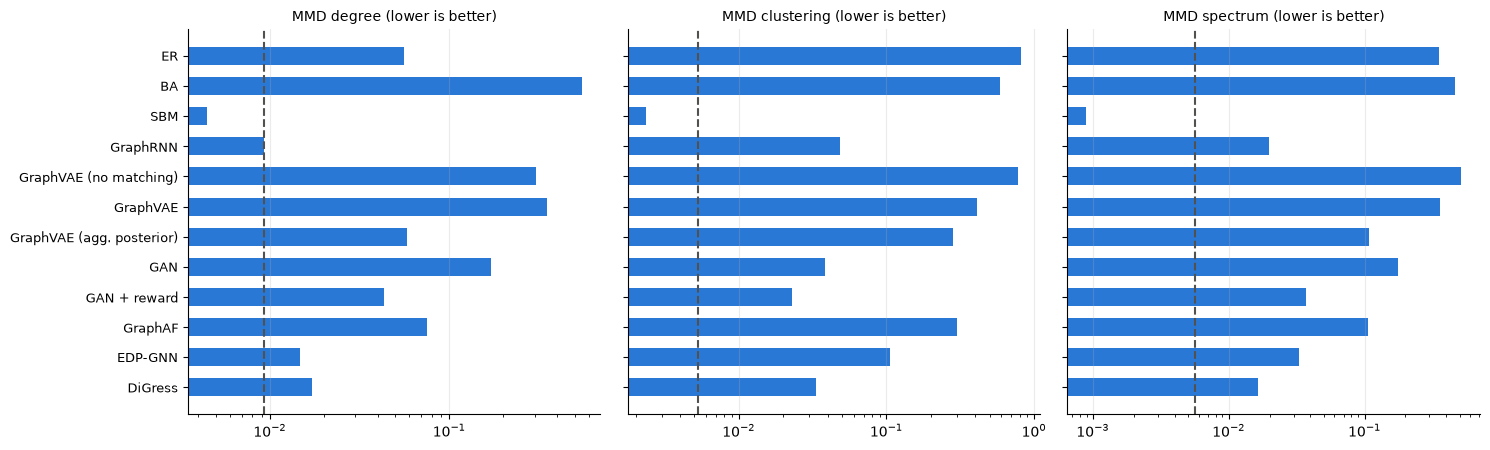

In [35]:
# MMD of every model (log scale; the grey line is the 'Data' floor: 200 training graphs vs. the test graphs)
names = ORDER[1:]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, (stat, title) in zip(axes, [('deg', 'degree'), ('clus', 'clustering'), ('spec', 'spectrum')]):
    values = [max(RESULTS[m][stat], 1e-4) for m in names]
    ax.barh(range(len(names)), values, color='#2a78d6', height=0.6)
    ax.axvline(RESULTS['Data'][stat], color='#52514e', ls='--', lw=1.5)
    ax.set_xscale('log')
    ax.set_title(f'MMD {title} (lower is better)', fontsize=10)
    ax.grid(axis='x', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_yticks(range(len(names)))
axes[0].set_yticklabels(names, fontsize=9)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

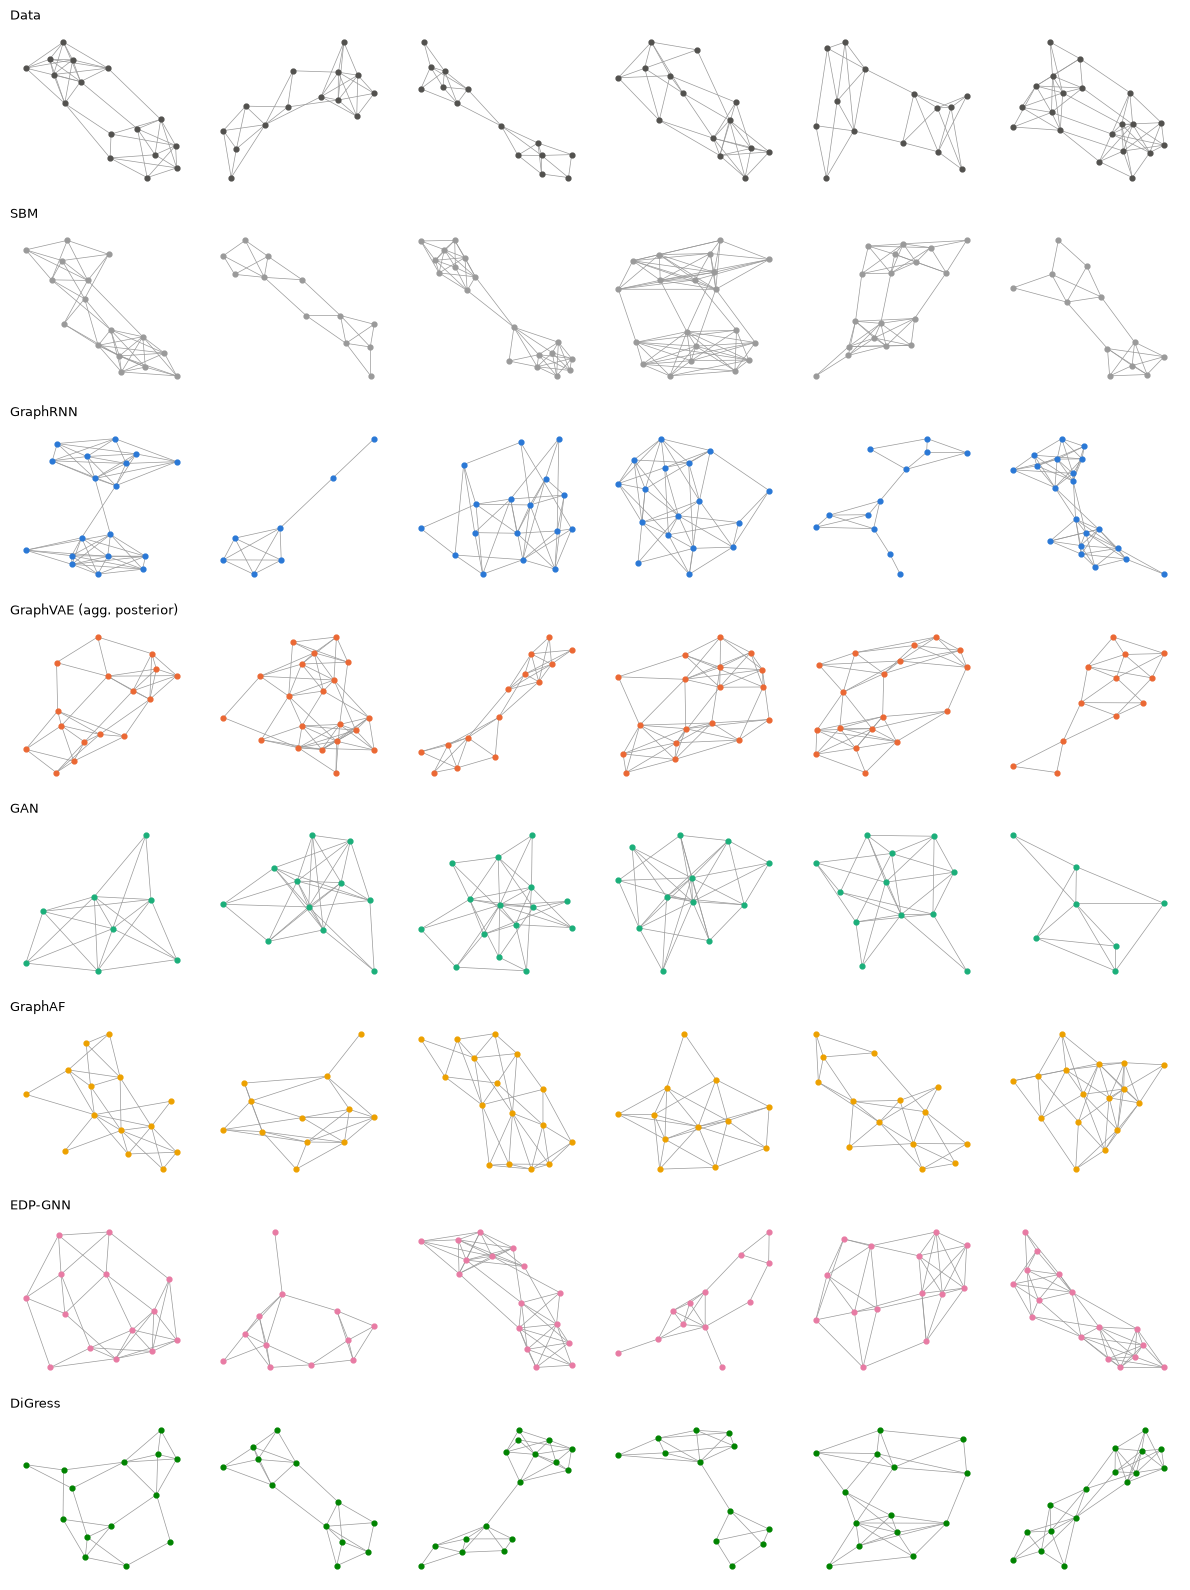

In [36]:
# Six samples of every generative model (one row per model)
rows = ['SBM', 'GraphRNN', 'GraphVAE (agg. posterior)', 'GAN', 'GraphAF', 'EDP-GNN', 'DiGress']
fig, axes = plt.subplots(len(rows) + 1, 6, figsize=(12, 2 * (len(rows) + 1)))
for r, name in enumerate(['Data'] + rows):
    graphs_r = test_graphs[:6] if name == 'Data' else SAMPLES[name][:6]
    for c, G in enumerate(graphs_r):
        ax = axes[r, c]
        nx.draw(G, nx.spring_layout(G, seed=0), ax=ax, node_size=12, width=0.5, edge_color='#999999',
                node_color=COLORS[name.split(' ')[0]] if name != 'Data' else '#52514e')
        ax.set_title(name if c == 0 else '', fontsize=9, loc='left')
plt.tight_layout()
plt.show()